# KelpAdam – UAS Pembelajaran Mesin
## Notebook B – Regresi Prediksi IPK dari Survei Preferensi Belajar (VARK)

**Tujuan:** memprediksi IPK (angka kontinu 0–4) dari jawaban 16 skenario VARK, lalu membandingkan **Linear Regression** dan **Random Forest Regressor** secara adil, dengan baseline sebagai patokan.

| Komponen | Isi |
|---|---|
| Sumber data | `dataset/processed_UTS/KelpAdam_survey_prepared.csv` (hasil notebook UTS, 192 responden) |
| Framework | VARK: 64 indikator 0/1 dari 16 skenario |
| Target y | `IPK` (kolom DL pada data dosen), numerik |
| Pembagian data | train 80% : test 20%, `random_state = 42` |
| Model | Baseline rerata, Linear Regression, Random Forest Regressor |
| Metrik | MAE, RMSE, R² pada test set |

**Alur notebook:** B0 Setup → B1 Data & definisi X/y → B2 Preprocessing & cleaning → B3 EDA → B4 Split & pipeline → B5 Training & pemilihan model → B6 Evaluasi test → B7 Simpan model.

**Batas interpretasi:** model ini hanya memeriksa apakah jawaban survei membantu memperkirakan IPK pada data yang tersedia. Hasilnya bukan bukti bahwa preferensi belajar *menyebabkan* IPK. Karena urutan waktu pengisian survei dan IPK tidak diketahui, model juga tidak diklaim sebagai prediksi dini.

---
# B0 – Setup

Semua library, konstanta, dan path didefinisikan di satu sel supaya notebook bisa dijalankan ulang dari awal (*Restart & Run All*).
- `SEED = 42` dan `TEST_SIZE = 0.2` sesuai spesifikasi UAS dan dipakai di seluruh notebook.
- Path dibuat **relatif terhadap folder proyek**, sama seperti notebook UTS kemarin, sehingga notebook berjalan di laptop anggota mana pun tanpa mengubah kode.
- Versi library dicetak sebagai bukti reproduksibilitas. Versi scikit-learn penting karena model `.joblib` hanya aman dimuat dengan versi yang sama.

In [1]:
import json
import platform
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, cross_val_predict, cross_validate,
                                     permutation_test_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --- Konstanta eksperimen (sesuai spesifikasi UAS) ---
SEED = 42          # random_state wajib
TEST_SIZE = 0.2    # train : test = 80 : 20

# --- Path relatif: notebook berada di <folder proyek>/notebook/ ---
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_FILE = PROJECT_DIR / "dataset" / "processed_UTS" / "KelpAdam_survey_prepared.csv"
DATA_OUT  = PROJECT_DIR / "dataset" / "processed_UAS"     # Dataset_regresi.csv
MODEL_DIR = PROJECT_DIR / "models"                        # Model_regresi.joblib
OUT_DIR   = PROJECT_DIR / "figures_and_outputs"           # grafik & tabel (prefix B)
for folder in (DATA_OUT, MODEL_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Tampilan tabel & grafik ---
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BIRU, ORANYE, ABU = "#2b6cb0", "#dd6b20", "#a0aec0"


def simpan_fig(fig, nama):
    """Simpan grafik ke figures_and_outputs/<nama>.png lalu tampilkan."""
    path = OUT_DIR / f"{nama}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    plt.show()
    print("Disimpan:", path.relative_to(PROJECT_DIR))


def simpan_tabel(tabel, nama):
    """Simpan tabel ke figures_and_outputs/<nama>.csv agar angka laporan bisa ditelusuri."""
    path = OUT_DIR / f"{nama}.csv"
    tabel.to_csv(path)
    print("Disimpan:", path.relative_to(PROJECT_DIR))


print("Folder proyek :", PROJECT_DIR)
print("File data     :", DATA_FILE.relative_to(PROJECT_DIR), "| ada?", DATA_FILE.exists())
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | joblib {joblib.__version__}")

Folder proyek : d:\Kuliah\Semester 5\Machine Learning\KelpAdam_UAS_MachineLearning
File data     : dataset\processed_UTS\KelpAdam_survey_prepared.csv | ada? True
Python 3.12.10 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | joblib 1.6.0


---
# B1 – Memuat data & mendefinisikan X dan y

## B1.1 Memuat dataset hasil UTS
Panduan UAS menyatakan bahwa *UAS menggunakan dataset yang dihasilkan pada UTS*. Dataset ini sudah melalui cleaning C1–C10 di notebook UTS (194 → 192 baris) dan berisi item mentah, skor, label, serta 64 indikator VARK. File UTS hanya **dibaca**, tidak diubah.

In [2]:
df = pd.read_csv(DATA_FILE)
print("Ukuran dataset:", df.shape)

# Memastikan ukuran harus sama dengan yang diharapkan
assert df.shape == (192, 216), "Ukuran berbeda dari output UTS; periksa file di dataset/processed_UTS/"
assert df["ID"].is_unique, "ID tidak unik"

# Menampilkan contoh 5 baris pertama dataset
display(df[["ID", "IPK", "VARK_Q01", "VARK_Q01_V", "VARK_Q01_A", "VARK_Q01_R", "VARK_Q01_K"]].head())

Ukuran dataset: (192, 216)


,ID,IPK,VARK_Q01,VARK_Q01_V,VARK_Q01_A,VARK_Q01_R,VARK_Q01_K
0,1,3.78,"melihat diagram, bagan, peta konsep, atau ilus...",1,1,0,0
1,2,3.83,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1
2,3,3.77,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1
3,4,1.97,"mencoba contoh, simulasi, praktik, atau meliha...",0,0,1,1
4,5,3.54,mendengar penjelasan dan dapat berdiskusi atau...,0,1,0,0


## B1.2 Alasan memilih framework VARK

| Alasan | Bukti |
|---|---|
| Semua framework sama-sama lemah hubungannya dengan IPK, jadi tidak ada framework yang jelas lebih unggul untuk regresi | EDA UTS (E6 lanjutan): korelasi setiap item dengan IPK paling besar \|ρ\| 0,20–0,23 di keempat framework, dan tidak ada yang signifikan setelah koreksi FDR |
| Tidak terdampak responden berpola seragam (*straightliner*) | Pola seragam ditemukan pada 88 item skala 1–5 (UTS C9); VARK berformat pilihan, dan jawaban VARK responden tersebut tetap bervariasi (dicek di B2.5) |
| Fitur sudah siap dan terverifikasi | 64 indikator 0/1 dibuat dan diverifikasi di UTS (S1, S5) |
| Konsisten dengan Proyek A (klasifikasi) | Satu skema input untuk kedua tab Streamlit dan satu fungsi encoding, sehingga risiko input aplikasi berbeda dengan training lebih kecil |

## B1.3 Definisi fitur X dan target y

- **X** = 64 kolom `VARK_Qxx_M`: `xx` = nomor skenario 01–16, `M` = modalitas V (Visual, opsi A), A (Aural, opsi B), R (Read/Write, opsi C), K (Kinesthetic, opsi D), sesuai Lampiran panduan. Nilai **1 = opsi dipilih**, **0 = tidak dipilih**. Satu skenario boleh punya lebih dari satu angka 1 karena pertanyaannya pilihan jamak.
- **y** = `IPK`, angka kontinu skala 0–4. IPK tidak diubah menjadi kategori karena tugas ini regresi.
- **Urutan kolom X dikunci** di `FEATURE_COLS`. Urutan yang sama wajib dipakai aplikasi Streamlit saat membuat input untuk model.

In [3]:
MODALITAS = ["V", "A", "R", "K"]   # urutan opsi A, B, C, D pada instrumen
FEATURE_COLS = [f"VARK_Q{q:02d}_{m}" for q in range(1, 17) for m in MODALITAS]
TARGET = "IPK"

assert len(FEATURE_COLS) == 64
kolom_hilang = [c for c in FEATURE_COLS if c not in df.columns]
assert not kolom_hilang, f"Kolom fitur tidak ditemukan: {kolom_hilang}"

print(f"Jumlah fitur X : {len(FEATURE_COLS)} (16 skenario x 4 modalitas)")
print("8 kolom pertama:", FEATURE_COLS[:8])
print("Target y       :", TARGET)

Jumlah fitur X : 64 (16 skenario x 4 modalitas)
8 kolom pertama: ['VARK_Q01_V', 'VARK_Q01_A', 'VARK_Q01_R', 'VARK_Q01_K', 'VARK_Q02_V', 'VARK_Q02_A', 'VARK_Q02_R', 'VARK_Q02_K']
Target y       : IPK


## B1.4 Kolom yang tidak dipakai sebagai fitur
Spesifikasi dan Panduan Regresi melarang memasukkan ID, IPS, label gaya belajar, skor ringkasan, dan item framework lain ke X. Sel berikut mengelompokkan **seluruh 216 kolom** beserta alasannya, lalu memastikan dengan `assert` bahwa X hanya berisi 64 indikator VARK.

In [4]:
SKOR_VARK = ["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]

def peran_kolom(kolom):
    """Kembalikan (kelompok, alasan) untuk setiap kolom dataset UTS."""
    if kolom == "ID":
        return "Identifier", "Nomor urut; hanya untuk melacak baris"
    if kolom == TARGET:
        return "Target y", "IPK numerik = target regresi"
    if kolom in FEATURE_COLS:
        return "Fitur X", "Indikator VARK 0/1"
    if kolom.startswith("IPS_"):
        return "IPS per semester", "Dilarang; IPK dihitung dari IPS sehingga membocorkan target"
    if kolom in SKOR_VARK:
        return "Skor VARK", "Skor ringkasan gaya belajar tidak boleh jadi fitur tambahan"
    if kolom.endswith("_label"):
        return "Label gaya belajar", "Dilarang sebagai fitur regresi"
    if kolom.startswith("VARK_Q"):
        return "Teks jawaban VARK", "Sudah diwakili 64 indikator; teks disimpan untuk audit"
    if kolom.startswith(("HM_", "FS_", "KOLB_")):
        return "Framework lain (item & skor)", "X hanya dari satu framework"
    return "Variabel bantu UTS", "Konteks/kualitas data (angkatan, flag), bukan item survei"

peran = pd.DataFrame([(c, *peran_kolom(c)) for c in df.columns], columns=["kolom", "kelompok", "alasan"])
ringkas_peran = (peran.groupby(["kelompok", "alasan"], sort=False)
                 .agg(jumlah_kolom=("kolom", "size"), contoh=("kolom", lambda s: ", ".join(s[:3])))
                 .reset_index().set_index("kelompok"))
display(ringkas_peran)

# Pengaman anti-leakage
assert ringkas_peran["jumlah_kolom"].sum() == df.shape[1] == 216
assert peran.loc[peran["kelompok"] == "Fitur X", "kolom"].tolist() == FEATURE_COLS
dilarang = peran.loc[~peran["kelompok"].isin(["Fitur X"]), "kolom"]
assert not set(FEATURE_COLS) & set(dilarang), "Ada kolom terlarang di X"
print("OK: X hanya berisi 64 indikator VARK; ID, IPS, skor, label, dan framework lain tidak masuk X.")

,alasan,jumlah_kolom,contoh
kelompok,,,
Identifier,Nomor urut; hanya untuk melacak baris,1,ID
IPS per semester,Dilarang; IPK dihitung dari IPS sehingga membo...,9,"IPS_2022_S1, IPS_2022_S2, IPS_2023_S1"
Target y,IPK numerik = target regresi,1,IPK
Teks jawaban VARK,Sudah diwakili 64 indikator; teks disimpan unt...,16,"VARK_Q01, VARK_Q02, VARK_Q03"
Framework lain (item & skor),X hanya dari satu framework,110,"HM_ACT_01, HM_ACT_02, HM_ACT_03"
Skor VARK,Skor ringkasan gaya belajar tidak boleh jadi f...,5,"VARK_V, VARK_A, VARK_R"
Label gaya belajar,Dilarang sebagai fitur regresi,4,"VARK_label, FS_ACT_REF_label, HM_label"
Variabel bantu UTS,"Konteks/kualitas data (angkatan, flag), bukan ...",6,"angkatan_inferred, n_semester_ips, row_sd"
Fitur X,Indikator VARK 0/1,64,"VARK_Q01_V, VARK_Q01_A, VARK_Q01_R"


OK: X hanya berisi 64 indikator VARK; ID, IPS, skor, label, dan framework lain tidak masuk X.


## B1.5 Pemeriksaan awal target IPK
Cek tipe data, jumlah yang terisi, dan rentang. IPK yang sah berada di **0 hingga 4**.

In [5]:
print("Tipe data IPK:", df[TARGET].dtype)
ipk_terisi = df[TARGET].dropna()

ringkas_ipk = df[TARGET].describe().to_frame("IPK (192 baris)").T
ringkas_ipk.insert(1, "kosong", df[TARGET].isna().sum())
display(ringkas_ipk.round(2))

n_luar = int((~ipk_terisi.between(0, 4)).sum())
assert n_luar == 0, "Ada IPK di luar rentang 0-4"
print(f"IPK terisi: {len(ipk_terisi)} | kosong: {df[TARGET].isna().sum()} | di luar 0-4: {n_luar}")

Tipe data IPK: float64


,count,kosong,mean,std,min,25%,50%,75%,max
IPK (192 baris),173.0,19,3.36,0.45,0.87,3.19,3.42,3.67,4.0


IPK terisi: 173 | kosong: 19 | di luar 0-4: 0


**Ringkasan B1:**
- Dataset UTS terbaca utuh: **192 baris × 216 kolom**.
- **X = 64 indikator VARK** dengan urutan fix; **y = IPK** bertipe numerik (`float64`).
- Seluruh kolom lain (ID, 9 kolom IPS, 5 skor VARK, 4 label, 16 teks jawaban VARK, 88 item + 22 skor framework lain, 6 variabel bantu) dikeluarkan, dan dibuktikan dengan `assert`.
- IPK terisi **173**, kosong **19**, dan **tidak ada** nilai di luar 0–4. Penanganan 19 IPK kosong dibahas di B2.3.

---
# B2 – Preprocessing & justifikasi cleaning

Cleaning utama sudah dikerjakan di notebook UTS:

| Langkah UTS | Isi | Dampak |
|---|---|---|
| C2 | Hapus 2 respons kosong total (ID 11, 133) | 194 → 192 baris |
| C3, C4 | Validasi jawaban 1–5 dan opsi VARK terhadap daftar resmi | 0 nilai tidak valid |
| C6 | IPK = 0 pada mahasiswa tanpa IPS sebelumnya → kosong (NaN), karena berarti "belum ada nilai" | 4 sel |
| C7 | Validasi rentang IPS/IPK 0–4 dan konsistensi IPK vs rata-rata IPS | IPK rendah tetap dipertahankan |
| C9 | Flag pola jawaban seragam (*straightliner*) pada 88 item skala 1–5, tidak dihapus | 15 responden ditandai |

Di bagian ini data dicek ulang **khusus untuk regresi**, lalu ditentukan baris mana yang dipakai.

**Catatan:** pada tahap ini belum ada transformasi yang *belajar dari data* (scaling, imputasi, seleksi fitur). Semua transformasi seperti itu dilakukan di dalam pipeline **setelah** split (B4), supaya tidak terjadi *data leakage*.

## B2.0 Verifikasi pengodean VARK (Panduan Regresi 3B)
Panduan meminta jawaban VARK diubah menjadi fitur dengan langkah berikut: (1) pecah teks per titik koma dan abaikan token kosong akibat pemisah terakhir, (2) cocokkan setiap teks dengan opsi pada Lampiran panduan (A = Visual, B = Aural, C = Read/Write, D = Kinesthetic), (3) buat 4 indikator 0/1 per skenario sehingga total 64 fitur. Skenario kosong dicatat sebagai *missing* (bukan empat nol), dan teks yang tidak cocok diperiksa sebelum dikodekan.

64 indikator di dataset sudah dibuat di UTS (S1). Karena UAS dikerjakan di notebook terpisah, sel berikut **membuat ulang** pengodean dari 16 kolom teks jawaban dengan aturan panduan, lalu membuktikan bahwa hasilnya **identik** dengan 64 kolom UTS. Fungsi `encode_vark` ini juga yang akan dipakai aplikasi Streamlit, sehingga pengodean input aplikasi terbukti sama dengan pengodean saat training.

In [6]:
# Teks opsi resmi per skenario, urutan [A=Visual, B=Aural, C=Read/Write, D=Kinesthetic] (Lampiran Panduan)
VARK_OPSI = {
    1: ["melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.",
        "mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.",
        "membaca uraian tertulis, definisi, atau catatan yang terstruktur.",
        "mencoba contoh, simulasi, praktik, atau melihat penerapan nyata."],
    2: ["mengikuti gambar langkah demi langkah atau tangkapan layar.",
        "meminta seseorang menjelaskan langkah-langkahnya secara lisan.",
        "membaca petunjuk tertulis dan daftar langkah.",
        "langsung mencoba sambil memperbaiki kesalahan yang muncul."],
    3: ["membuat peta konsep, skema, warna, atau diagram.",
        "menjelaskan materi dengan suara keras atau berdiskusi dengan teman.",
        "menulis ulang ringkasan, membuat daftar, atau membaca catatan.",
        "berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman."],
    4: ["ada visualisasi yang menunjukkan hubungan antar konsep.",
        "penjelasan disampaikan dengan contoh verbal dan tanya jawab.",
        "tersedia teks atau rumusan tertulis yang dapat saya baca kembali.",
        "ada demonstrasi, studi kasus, atau aktivitas langsung."],
    5: ["melihat contoh hasil akhir atau struktur visual tugas.",
        "mendengarkan penjelasan dosen tentang apa yang harus dilakukan.",
        "membaca instruksi dan rubrik secara rinci.",
        "mencoba bagian awal tugas untuk memahami apa yang diminta."],
    6: ["melihat peta atau petunjuk arah visual.",
        "bertanya kepada orang lain dan mendengarkan arahannya.",
        "membaca nama jalan, papan petunjuk, atau instruksi tertulis.",
        "berjalan mencoba rute sambil menyesuaikan arah."],
    7: ["grafik, diagram, dan visualisasi pola.",
        "penjelasan lisan tentang makna hasil.",
        "tabel, uraian tertulis, dan penjelasan metodologis.",
        "contoh penerapan data pada kasus nyata."],
    8: ["menggambar skema atau menunjukkan visual.",
        "menjelaskannya melalui percakapan.",
        "menuliskan poin-poin atau memberi bacaan singkat.",
        "menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi."],
    9: ["infografik, diagram, atau video dengan visual yang jelas.",
        "rekaman audio, diskusi sinkron, atau penjelasan verbal.",
        "modul teks, transkrip, dan catatan yang lengkap.",
        "simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus."],
    10: ["membuat sketsa atau memetakan masalah secara visual.",
         "membicarakan masalah dengan orang lain untuk memperoleh ide.",
         "menuliskan fakta, alternatif, dan langkah pemecahan.",
         "mencoba beberapa solusi dan belajar dari hasil percobaan."],
    11: ["video animasi, diagram interaktif, atau infografik.",
         "podcast, rekaman kuliah, atau diskusi kelompok.",
         "artikel, buku, modul, atau catatan tertulis.",
         "tutorial praktik, proyek, eksperimen, atau studi kasus."],
    12: ["dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.",
         "dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.",
         "dapat menuliskan definisi dan penjelasannya secara runtut.",
         "dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata."],
    13: ["mencari bagian visual terlebih dahulu untuk memahami gambaran besar.",
         "mendengarkan penjelasan terkait sebelum atau sambil belajar.",
         "membaca dan membuat catatan secara sistematis.",
         "mencari latihan atau contoh penerapan setelah memahami pokok materi."],
    14: ["ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.",
         "dibicarakan secara langsung sehingga saya dapat bertanya.",
         "diberikan komentar tertulis yang rinci.",
         "diberi kesempatan mencoba revisi dan melihat dampaknya."],
    15: ["menyusun bagan, desain, atau struktur visual.",
         "berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.",
         "menulis dokumen, rangkuman, atau notulen.",
         "mengerjakan prototipe, praktik, atau implementasi."],
    16: ["melihat representasi visual tentang bagaimana hal itu bekerja.",
         "mendengar seseorang menjelaskannya dan berdialog.",
         "membaca penjelasan tertulis yang lengkap.",
         "mengalami atau mencoba secara langsung."],
}
assert len(VARK_OPSI) == 16 and all(len(v) == 4 for v in VARK_OPSI.values())


def normalisasi(teks):
    """Samakan format teks: huruf kecil, spasi tunggal, tanpa titik di akhir."""
    return " ".join(str(teks).lower().split()).rstrip(".")


# Peta teks opsi -> modalitas, per skenario
PETA_OPSI = {q: {normalisasi(t): m for t, m in zip(opsi, MODALITAS)} for q, opsi in VARK_OPSI.items()}


def encode_vark(jawaban):
    """Ubah 16 jawaban teks VARK menjadi 64 indikator 0/1.

    jawaban: list/Series berisi 16 teks (skenario 1-16); satu teks bisa memuat beberapa opsi dipisah ';'.
    Mengembalikan (indikator, tidak_cocok):
      - indikator  : dict 64 kolom; skenario kosong -> NaN (bukan empat nol)
      - tidak_cocok: list (skenario, token) yang tidak ada di daftar opsi resmi
    """
    indikator, tidak_cocok = {}, []
    for q, teks in zip(range(1, 17), jawaban):
        token = [] if pd.isna(teks) else [t for t in str(teks).split(";") if t.strip()]  # buang token kosong
        dipilih = set()
        for t in token:
            m = PETA_OPSI[q].get(normalisasi(t))
            if m is None:
                tidak_cocok.append((q, t.strip()))
            else:
                dipilih.add(m)
        for m in MODALITAS:
            indikator[f"VARK_Q{q:02d}_{m}"] = (1 if m in dipilih else 0) if token else np.nan
    return indikator, tidak_cocok

Contoh cara kerja fungsi pada satu jawaban, termasuk format mentah dari data dosen yang selalu diakhiri `;` (menghasilkan token kosong di akhir yang harus diabaikan):

In [7]:
contoh = df.loc[df["ID"] == 1, "VARK_Q01"].iloc[0]
contoh_mentah = contoh.replace("; ", ";") + ";"   # format asli data dosen: "opsi a;opsi b;"
print("Jawaban mentah skenario 1 (ID 1):", repr(contoh_mentah))
print("Token setelah dipecah           :", contoh_mentah.split(";"))

hasil_contoh, _ = encode_vark([contoh_mentah] + [np.nan] * 15)
print("Indikator skenario 1            :", {k: v for k, v in hasil_contoh.items() if k.startswith("VARK_Q01_")})
print("Indikator skenario 2 (kosong)   :", {k: v for k, v in hasil_contoh.items() if k.startswith("VARK_Q02_")})

Jawaban mentah skenario 1 (ID 1): 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.;'
Token setelah dipecah           : ['melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.', 'mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.', '']
Indikator skenario 1            : {'VARK_Q01_V': 1, 'VARK_Q01_A': 1, 'VARK_Q01_R': 0, 'VARK_Q01_K': 0}
Indikator skenario 2 (kosong)   : {'VARK_Q02_V': nan, 'VARK_Q02_A': nan, 'VARK_Q02_R': nan, 'VARK_Q02_K': nan}


In [8]:
# Terapkan ke seluruh 192 responden, lalu bandingkan dengan 64 kolom hasil UTS
TEKS_COLS = [f"VARK_Q{q:02d}" for q in range(1, 17)]
hasil = [encode_vark(baris) for baris in df[TEKS_COLS].itertuples(index=False)]
X_encode = pd.DataFrame([h[0] for h in hasil], index=df.index)[FEATURE_COLS]
tidak_cocok = [(df.at[i, "ID"], q, t) for i, (_, tc) in zip(df.index, hasil) for q, t in tc]

n_skenario_kosong_teks = int(df[TEKS_COLS].isna().sum().sum())
n_beda = int((X_encode.fillna(-1) != df[FEATURE_COLS]).sum().sum())   # NaN dihitung sebagai beda

display(pd.DataFrame({"Hasil": {
    "Responden diperiksa": len(df),
    "Skenario kosong (missing)": n_skenario_kosong_teks,
    "Token teks tidak cocok dengan opsi resmi": len(tidak_cocok),
    "Sel berbeda dengan 64 indikator UTS": n_beda,
}}))
assert n_skenario_kosong_teks == 0 and not tidak_cocok and n_beda == 0
print("OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.")

,Hasil
Responden diperiksa,192
Skenario kosong (missing),0
Token teks tidak cocok dengan opsi resmi,0
Sel berbeda dengan 64 indikator UTS,0


OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.


**Temuan B2.0:** seluruh 192 responden menjawab ke-16 skenario (0 skenario kosong), semua teks cocok dengan opsi resmi (0 tidak cocok), dan hasil pengodean ulang **identik** dengan 64 indikator UTS (0 sel berbeda). Fitur X yang dipakai di notebook ini terbukti mengikuti aturan Panduan §3B.

**Catatan nilai 0:** pada fitur X, angka **0 adalah nilai sah** yang berarti "opsi tidak dipilih" pada skenario yang dijawab. Ini berbeda dengan IPK = 0 pada data dosen, yang merupakan **kode "belum ada nilai"** (dibahas di B2.3).

## B2.1 Validasi fitur X
Yang dicek adalah tidak ada sel kosong, semua nilai harus 0/1, dan **setiap skenario punya minimal satu opsi dipilih**. Panduan melarang menyamakan jawaban VARK kosong dengan "empat nol", jadi kondisi ini harus 0.

In [9]:
X_semua = df[FEATURE_COLS]
n_nan = int(X_semua.isna().sum().sum())
n_bukan_biner = int((~X_semua.isin([0, 1])).sum().sum())
n_skenario_kosong = int(sum(
    (X_semua[[f"VARK_Q{q:02d}_{m}" for m in MODALITAS]].sum(axis=1) == 0).sum() for q in range(1, 17)))

display(pd.DataFrame({"Hasil": {
    "Tipe data fitur": ", ".join(sorted(X_semua.dtypes.astype(str).unique())),
    "Sel kosong (NaN)": n_nan,
    "Nilai selain 0/1": n_bukan_biner,
    "Skenario tanpa opsi dipilih": n_skenario_kosong,
}}))
assert n_nan == 0 and n_bukan_biner == 0 and n_skenario_kosong == 0
print("OK: 64 fitur lengkap, biner, dan setiap skenario dijawab.")

,Hasil
Tipe data fitur,int64
Sel kosong (NaN),0
Nilai selain 0/1,0
Skenario tanpa opsi dipilih,0


OK: 64 fitur lengkap, biner, dan setiap skenario dijawab.


## B2.2 Duplikasi
Dicek dua hal:
- **(a)** baris yang identik di X **dan** IPK (duplikat sungguhan);
- **(b)** baris yang X-nya identik tetapi IPK-nya bisa berbeda.

Kasus (b) bukan duplikat jika IPK-nya berbeda, karena berarti dua orang berbeda yang kebetulan memilih opsi VARK yang sama.

In [10]:
dup_x_y = int(df.duplicated(subset=FEATURE_COLS + [TARGET]).sum())
sama_x = df[df.duplicated(subset=FEATURE_COLS, keep=False)]
print("Duplikat X + IPK :", dup_x_y)
print("Baris dengan pola X identik:", len(sama_x))
display(sama_x[["ID", TARGET, "VARK_total"]])

Duplikat X + IPK : 0
Baris dengan pola X identik: 2


,ID,IPK,VARK_total
113,115,3.57,16
121,123,2.95,16


**Temuan:** tidak ada duplikat sungguhan. Ada 2 responden (ID 115 dan 123) yang memilih opsi VARK yang persis sama (masing-masing tepat 1 opsi per skenario), tetapi IPK-nya berbeda (3,57 vs 2,95). Keduanya **dipertahankan** karena merupakan orang berbeda. Kasus ini sekaligus menunjukkan batas model: input yang identik bisa memiliki IPK yang berbeda 0,6 poin.

*(`VARK_total` hanya ditampilkan untuk audit, tidak dipakai sebagai fitur.)*

## B2.3 Alasan IPK Kosong tidak diimputasi
Panduan Regresi 2.4 menjelaskan bahwa *IPK yang hilang tidak boleh diisi dengan rerata atau hasil prediksi.* Sel berikut menguraikan asal 19 IPK kosong. ID IPK = 0 yang di-recode diambil dari cleaning log UTS langkah C6.

In [11]:
ID_IPK_NOL_C6 = [20, 29, 59, 82]   # IPK = 0 di data dosen -> NaN (cleaning log UTS, langkah C6)

def asal_ipk_kosong(baris):
    if baris["ID"] in ID_IPK_NOL_C6:
        return "IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6"
    if baris["angkatan_inferred"] == "2026":
        return "Mahasiswa baru angkatan 2026, IPK kosong di data dosen"
    return "Tidak punya IPS maupun IPK sama sekali"

tanpa_ipk = df[df[TARGET].isna()].copy()
tanpa_ipk["asal"] = tanpa_ipk.apply(asal_ipk_kosong, axis=1)
tabel_ipk_kosong = (tanpa_ipk.groupby("asal")
                    .agg(jumlah=("ID", "size"), ID=("ID", lambda s: ", ".join(map(str, s))))
                    .sort_values("jumlah", ascending=False))
display(tabel_ipk_kosong)

assert tabel_ipk_kosong["jumlah"].sum() == 19
assert (tanpa_ipk["n_semester_ips"] == 0).all(), "Ada responden tanpa IPK yang punya riwayat IPS"
print("Semua 19 responden tanpa IPK juga tidak punya riwayat IPS (n_semester_ips = 0).")

,jumlah,ID
asal,,
Tidak punya IPS maupun IPK sama sekali,8,"17, 83, 127, 144, 169, 192, 193, 194"
"Mahasiswa baru angkatan 2026, IPK kosong di data dosen",7,"145, 151, 156, 165, 167, 170, 179"
IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6,4,"20, 29, 59, 82"


Semua 19 responden tanpa IPK juga tidak punya riwayat IPS (n_semester_ips = 0).


**Keputusan:** ke-19 responden ini **dikeluarkan dari data regresi** dan IPK-nya **tidak diimputasi**.
- Ke-19 responden tidak punya satu pun nilai IPS, sehingga IPK-nya memang belum ada (mahasiswa baru) atau tidak tersedia, bukan lupa diisi.
- Mengisi target dengan rerata atau prediksi berarti membuat jawaban yang akan diprediksi model sendiri. Hal ini dilarang panduan dan akan membuat evaluasi bias.
- Responden ini tetap dipakai di Proyek A (klasifikasi), karena di sana targetnya label VARK, bukan IPK.

In [12]:
df_reg = df[df[TARGET].notna()].copy()
print(f"Data regresi: {len(df)} -> {len(df_reg)} baris ({len(df) - len(df_reg)} tanpa IPK dikeluarkan)")

Data regresi: 192 -> 173 baris (19 tanpa IPK dikeluarkan)


## B2.4 Nilai IPK ekstrem: dipertahankan
Nilai ekstrem dideteksi dengan aturan boxplot (di bawah Q1 − 1,5 × IQR). Nilai ekstrem **tidak dihapus otomatis**: yang dibuang hanya nilai yang *tidak mungkin*, sedangkan IPK rendah masih mungkin terjadi.

In [13]:
q1, q3 = df_reg[TARGET].quantile([0.25, 0.75])
batas_bawah = q1 - 1.5 * (q3 - q1)
ekstrem = df_reg[df_reg[TARGET] < batas_bawah]
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | batas bawah = {batas_bawah:.2f} | jumlah ekstrem bawah = {len(ekstrem)}")
display(ekstrem[["ID", TARGET, "n_semester_ips", "angkatan_inferred"]].sort_values(TARGET))

Q1 = 3.19 | Q3 = 3.67 | batas bawah = 2.47 | jumlah ekstrem bawah = 8


,ID,IPK,n_semester_ips,angkatan_inferred
28,30,0.87,1,2025
3,4,1.97,4,2024
6,7,2.17,2,2025
131,134,2.24,5,2024
16,18,2.29,2,2025
134,137,2.38,2,2025
172,175,2.38,5,2024
110,112,2.43,4,2024


**Keputusan:** 8 IPK ekstrem bawah (0,87–2,43) **dipertahankan**.
- Semuanya berada dalam rentang sah 0–4, dan di UTS (C7) IPK terbukti konsisten dengan rata-rata IPS (selisih maksimum 0,21), jadi bukan salah input.
- Semuanya punya riwayat IPS (1–5 semester).
- Membuang IPK rendah akan membuat model hanya belajar dari mahasiswa ber-IPK tinggi. **Dampak yang diperkirakan:** karena jumlahnya sedikit, error terbesar kemungkinan terjadi pada kelompok ini. Hal ini akan diperiksa di B6.

## B2.5 Responden berpola seragam (straightliner): dipertahankan
Flag `flag_straightline` dari UTS dibuat berdasarkan 88 item skala 1–5, **bukan** dari VARK. Sel berikut memeriksa apakah jawaban VARK responden tersebut juga seragam.

In [14]:
sl = df_reg[df_reg["flag_straightline"]]
print(f"Straightliner yang punya IPK: {len(sl)} dari {int(df['flag_straightline'].sum())}")
print(f"Jumlah opsi VARK yang dipilih (dari 64): min {sl['VARK_total'].min()}, "
      f"median {sl['VARK_total'].median():.0f}, max {sl['VARK_total'].max()}")

Straightliner yang punya IPK: 13 dari 15
Jumlah opsi VARK yang dipilih (dari 64): min 16, median 31, max 64


**Keputusan:** ke-13 straightliner yang punya IPK **dipertahankan**. Jumlah opsi VARK yang mereka pilih bervariasi (16 sampai 64), jadi jawaban VARK mereka tidak seragam seperti jawaban skala 1–5 mereka, dan tidak ada dasar untuk membuangnya dari model berbasis VARK.

## B2.6 Ringkasan cleaning & ekspor `Dataset_regresi.csv`
Sesuai Panduan Regresi pada poin 3 (*"Dataset modeling: hanya X1, X2, ..., Xn dan IPK"*), `Dataset_regresi.csv` hanya berisi **64 fitur X** dan **IPK**. Kolom `ID` **tidak** ikut disimpan. Di dalam notebook, `ID` tetap ada di `df_reg` (bukan di X) agar contoh error di B6 bisa ditelusuri ke responden.

In [15]:
log_regresi = pd.DataFrame([
    ("Dataset UTS (setelah cleaning C1-C10)", 192, 192, "Titik awal"),
    ("Keluarkan responden tanpa IPK", 192, len(df_reg), "Target tidak tersedia; tidak diimputasi (B2.3)"),
    ("IPK ekstrem bawah", len(df_reg), len(df_reg), f"{len(ekstrem)} baris dipertahankan; nilai sah (B2.4)"),
    ("Straightliner", len(df_reg), len(df_reg), f"{len(sl)} baris dipertahankan; jawaban VARK bervariasi (B2.5)"),
    ("Duplikat X + IPK", len(df_reg), len(df_reg), f"{dup_x_y} duplikat (B2.2)"),
], columns=["langkah", "baris_sebelum", "baris_sesudah", "keterangan"]).set_index("langkah")
display(log_regresi)
simpan_tabel(log_regresi, "B2_log_cleaning_regresi")

dataset_regresi = df_reg[FEATURE_COLS + [TARGET]].reset_index(drop=True)   # hanya X + IPK, tanpa ID
path_dataset = DATA_OUT / "Dataset_regresi.csv"
dataset_regresi.to_csv(path_dataset, index=False)

# Verifikasi: file yang disimpan bisa dibaca ulang dan isinya sama
cek = pd.read_csv(path_dataset)
pd.testing.assert_frame_equal(cek, dataset_regresi)
assert list(cek.columns) == FEATURE_COLS + [TARGET], "Kolom dataset harus 64 fitur + IPK saja"
print("Disimpan:", path_dataset.relative_to(PROJECT_DIR), "| ukuran:", cek.shape, "(64 fitur + IPK)")

,baris_sebelum,baris_sesudah,keterangan
langkah,,,
Dataset UTS (setelah cleaning C1-C10),192,192,Titik awal
Keluarkan responden tanpa IPK,192,173,Target tidak tersedia; tidak diimputasi (B2.3)
IPK ekstrem bawah,173,173,8 baris dipertahankan; nilai sah (B2.4)
Straightliner,173,173,13 baris dipertahankan; jawaban VARK bervarias...
Duplikat X + IPK,173,173,0 duplikat (B2.2)


Disimpan: figures_and_outputs\B2_log_cleaning_regresi.csv
Disimpan: dataset\processed_UAS\Dataset_regresi.csv | ukuran: (173, 65) (64 fitur + IPK)


**Ringkasan B2:**
- Fitur X bersih: 64 kolom biner, 0 kosong, setiap skenario dijawab. **Tidak perlu imputasi fitur.**
- **192 → 173 baris**: hanya 19 responden tanpa IPK yang dikeluarkan, dan targetnya tidak diimputasi.
- 8 IPK ekstrem bawah dan 13 straightliner **dipertahankan** dengan alasan tertulis. Tidak ada duplikat sungguhan.
- Pengodean VARK dibuktikan ulang sesuai Panduan §3B dan identik dengan UTS (B2.0).
- `Dataset_regresi.csv` (**173 × 65**: 64 fitur + IPK, tanpa ID) tersimpan di `dataset/processed_UAS/`.

---
# B3 – Exploratory Data Analysis (EDA)

Panduan Regresi §2 meminta empat hal. Pemeriksaan dasar (poin 1, 2, 4) sudah dilakukan dan dibuktikan dengan `assert` di B1–B2, sehingga **tidak diulang** di sini. Bagian B3 berfokus pada poin 3: tabel kondisi bermasalah, distribusi IPK, ringkasan fitur, dan hubungan fitur dengan IPK.

| Poin Panduan §2 | Sudah ada di | Hasil singkat |
|---|---|---|
| 1. Ukuran dataset, nama/tipe kolom, contoh respons, statistik dasar IPK | B1.1, B1.4, B1.5 | 192 × 216; X = 64 indikator `int64`; IPK `float64`, 173 terisi |
| 1. Statistik deskriptif fitur | **B3.3** | Persentase responden yang memilih setiap opsi |
| 2. Nilai kosong/null, duplikasi, respons tidak valid | B2.0, B2.1, B2.2 | 0 kosong, 0 nilai bukan 0/1, 0 teks tidak cocok, 0 duplikat |
| 2. IPK di luar rentang; nilai 0 yang benar vs kode "belum ada" | B1.5, B2.0, B2.3 | 0 di luar 0–4; 0 pada fitur = "tidak dipilih" (sah), IPK = 0 = kode belum ada nilai |
| 3. Tabel jumlah kondisi bermasalah + keputusan + dampak jumlah data | **B3.1** | Ringkasan semua kondisi dalam satu tabel |
| 3. Grafik distribusi IPK | **B3.2** | Histogram + boxplot |
| 3. Visualisasi hubungan beberapa fitur dengan IPK | **B3.4** | Korelasi 64 indikator + boxplot indikator terkuat |
| 4. Target tidak diimputasi; fitur hilang ditangani di training | B2.3, B2.1 | 19 IPK kosong dikeluarkan; fitur tidak ada yang hilang |

**Catatan leakage:** EDA dilakukan pada 173 baris sebelum split dan bersifat **deskriptif saja**. Hasil EDA (misalnya korelasi fitur–IPK) **tidak** dipakai untuk memilih atau membuang fitur. Seluruh 64 fitur tetap dipakai sesuai panduan, dan semua transformasi yang belajar dari data dilakukan di dalam pipeline setelah split (B4).

## B3.1 Tabel kondisi bermasalah
Semua temuan kualitas data dari B1–B2 dikumpulkan dalam satu tabel: berapa jumlahnya, apa keputusannya, dan berapa baris yang hilang karenanya.

In [16]:
n_asal = tabel_ipk_kosong["jumlah"]
kondisi = pd.DataFrame([
    ("IPK kosong: tidak punya IPS maupun IPK",  n_asal["Tidak punya IPS maupun IPK sama sekali"], "Dikeluarkan, tidak diimputasi", "B2.3"),
    ("IPK kosong: mahasiswa baru angkatan 2026", n_asal["Mahasiswa baru angkatan 2026, IPK kosong di data dosen"], "Dikeluarkan, tidak diimputasi", "B2.3"),
    ("IPK = 0 sebagai kode 'belum ada nilai'",   n_asal["IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6"], "Sudah NaN sejak UTS C6; dikeluarkan", "B2.3"),
    ("IPK di luar rentang 0-4",                  n_luar, "-", "B1.5"),
    ("Fitur X kosong (NaN)",                     n_nan, "-", "B2.1"),
    ("Nilai fitur selain 0/1",                   n_bukan_biner, "-", "B2.1"),
    ("Skenario VARK tidak dijawab",              n_skenario_kosong_teks, "-", "B2.0"),
    ("Teks jawaban VARK tidak cocok opsi resmi", len(tidak_cocok), "-", "B2.0"),
    ("Duplikat X + IPK",                         dup_x_y, "-", "B2.2"),
    ("Pola X identik tetapi IPK berbeda",        len(sama_x), "Dipertahankan (orang berbeda)", "B2.2"),
    ("IPK ekstrem bawah (< Q1 - 1,5 IQR)",       len(ekstrem), "Dipertahankan (nilai sah)", "B2.4"),
    ("Straightliner (skala 1-5) yang punya IPK", len(sl), "Dipertahankan (jawaban VARK bervariasi)", "B2.5"),
], columns=["kondisi", "jumlah", "keputusan", "bagian"])
kondisi["baris_dikeluarkan"] = np.where(kondisi["keputusan"].str.contains("ikeluarkan"), kondisi["jumlah"], 0)
kondisi = kondisi.set_index("kondisi")
display(kondisi)
simpan_tabel(kondisi, "B3_1_kondisi_bermasalah")

assert kondisi["baris_dikeluarkan"].sum() == len(df) - len(df_reg)
print(f"Total dikeluarkan: {kondisi['baris_dikeluarkan'].sum()} baris -> data regresi {len(df)} - "
      f"{kondisi['baris_dikeluarkan'].sum()} = {len(df_reg)} baris")

,jumlah,keputusan,bagian,baris_dikeluarkan
kondisi,,,,
IPK kosong: tidak punya IPS maupun IPK,8,"Dikeluarkan, tidak diimputasi",B2.3,8
IPK kosong: mahasiswa baru angkatan 2026,7,"Dikeluarkan, tidak diimputasi",B2.3,7
IPK = 0 sebagai kode 'belum ada nilai',4,Sudah NaN sejak UTS C6; dikeluarkan,B2.3,4
IPK di luar rentang 0-4,0,-,B1.5,0
Fitur X kosong (NaN),0,-,B2.1,0
Nilai fitur selain 0/1,0,-,B2.1,0
Skenario VARK tidak dijawab,0,-,B2.0,0
Teks jawaban VARK tidak cocok opsi resmi,0,-,B2.0,0
Duplikat X + IPK,0,-,B2.2,0


Disimpan: figures_and_outputs\B3_1_kondisi_bermasalah.csv
Total dikeluarkan: 19 baris -> data regresi 192 - 19 = 173 baris


**Interpretasi B3.1**
- Dari 12 kondisi yang dicek, hanya 3 yang membuat baris dikeluarkan, dan ketiganya soal IPK yang memang tidak ada (total 19 baris). Masalah format (sel kosong, nilai aneh, teks tidak cocok, duplikat) semuanya **0**. Tiga kondisi lain (pola X identik, IPK ekstrem, straightliner) sengaja **dipertahankan**.
- **Artinya:** data survei sudah bersih sejak UTS. Satu-satunya data yang hilang berasal dari target yang belum tersedia, bukan dari kesalahan pengisian.
- **Dampak ke modeling:** data regresi = **173 baris**, dan pipeline **tidak perlu imputer** karena fitur tidak ada yang kosong.

## B3.2 Distribusi IPK (target)
Pertanyaan: **seperti apa sebaran IPK yang akan diprediksi?** Bentuk sebaran target menentukan cara membaca error model nanti.

,n,rata-rata,median,simpangan baku,min,Q1,Q3,max,skewness,"% IPK >= 3,00","% IPK >= 3,50",jumlah ekstrem bawah
IPK,173.0,3.36,3.42,0.45,0.87,3.19,3.67,4.0,-1.63,82.08,45.66,8.0


Disimpan: figures_and_outputs\B3_2_statistik_ipk.csv


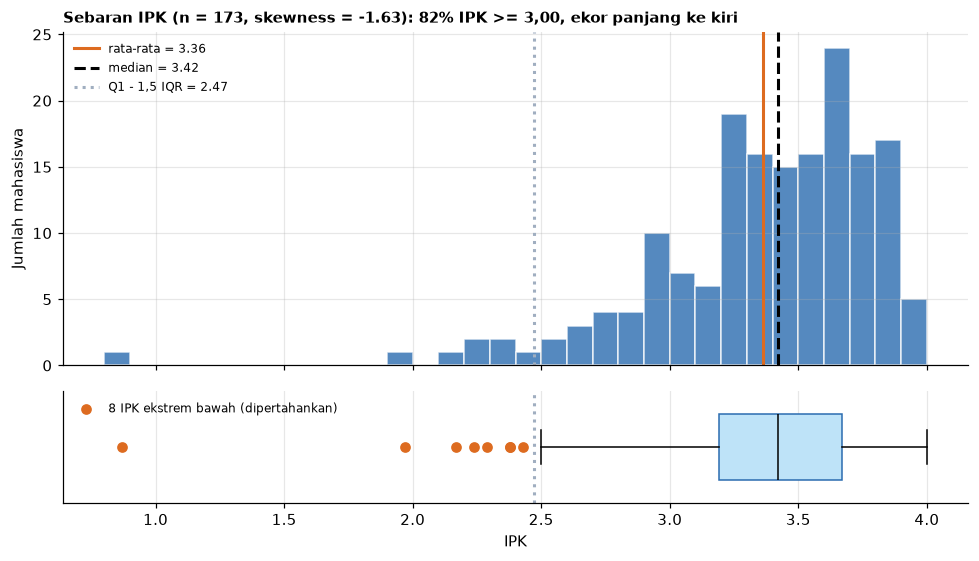

Disimpan: figures_and_outputs\B3_2_distribusi_ipk.png


In [17]:
ipk = df_reg[TARGET]
stat_ipk = pd.Series({
    "n": len(ipk), "rata-rata": ipk.mean(), "median": ipk.median(), "simpangan baku": ipk.std(),
    "min": ipk.min(), "Q1": q1, "Q3": q3, "max": ipk.max(), "skewness": stats.skew(ipk),
    "% IPK >= 3,00": (ipk >= 3.0).mean() * 100, "% IPK >= 3,50": (ipk >= 3.5).mean() * 100,
    "jumlah ekstrem bawah": len(ekstrem),
}).round(2).to_frame("IPK")
display(stat_ipk.T)
simpan_tabel(stat_ipk, "B3_2_statistik_ipk")

# boxplot horizontal; parameter berbeda antar versi matplotlib
ARAH_HORIZONTAL = ({"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10)
                   else {"vert": False})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.hist(ipk, bins=np.arange(0.8, 4.05, 0.1), color=BIRU, alpha=0.8, edgecolor="white")
ax1.axvline(ipk.mean(), color=ORANYE, lw=2, label=f"rata-rata = {ipk.mean():.2f}")
ax1.axvline(ipk.median(), color="black", lw=2, ls="--", label=f"median = {ipk.median():.2f}")
ax1.axvline(batas_bawah, color=ABU, lw=2, ls=":", label=f"Q1 - 1,5 IQR = {batas_bawah:.2f}")
ax1.set_ylabel("Jumlah mahasiswa")
ax1.set_title(f"Sebaran IPK (n = {len(ipk)}, skewness = {stats.skew(ipk):.2f}): {(ipk >= 3).mean() * 100:.0f}% IPK >= 3,00, "
              f"ekor panjang ke kiri",
              loc="left", fontsize=10, fontweight="bold")
ax1.legend(frameon=False, fontsize=8, loc="upper left")

ax2.boxplot(ipk, **ARAH_HORIZONTAL, widths=0.6, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor="#bee3f8", color=BIRU), medianprops=dict(color="black"))
ax2.scatter(ekstrem[TARGET], np.ones(len(ekstrem)), color=ORANYE, zorder=3, label=f"{len(ekstrem)} IPK ekstrem bawah (dipertahankan)")
ax2.axvline(batas_bawah, color=ABU, lw=2, ls=":")
ax2.set_yticks([])
ax2.set_xlabel("IPK")
ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
simpan_fig(fig, "B3_2_distribusi_ipk")

**Interpretasi B3.2**
- **Yang terlihat:** sebagian besar mahasiswa ber-IPK tinggi: 82% punya IPK ≥ 3,00 dan hampir separuh (46%) ≥ 3,50. Median (3,42) lebih besar dari rata-rata (3,36), karena rata-rata "tertarik" ke bawah oleh sedikit IPK rendah. Skewness −1,63 berarti sebarannya **menceng kiri**: menumpuk di nilai tinggi dengan ekor panjang ke arah nilai rendah. Ada 8 IPK di bawah 2,47, dan yang paling ekstrem (0,87) jauh terpisah dari yang lain.
- **Artinya:** IPK rendah adalah kasus langka di data ini. Model yang belajar dari data seperti ini cenderung menebak di sekitar 3,3–3,4, sehingga untuk mahasiswa ber-IPK rendah tebakannya akan terlalu tinggi.
- **Dampak ke modeling:**
  - Error terbesar diperkirakan ada di IPK rendah. Ini akan dicek di B6 dengan MAE per kelompok IPK.
  - **MAE** dipakai sebagai metrik utama karena paling mudah dibaca ("rata-rata tebakan meleset berapa poin IPK"). **RMSE** diperkirakan lebih besar dari MAE karena RMSE menghukum tebakan yang meleset jauh, dan tebakan seperti itu datang dari IPK rendah.
  - Model baru dianggap berguna kalau error-nya **lebih kecil daripada sekadar menebak rata-rata IPK** (baseline di B5).
  - IPK **tidak ditransformasi** (misalnya log), supaya prediksi langsung berada di skala IPK asli 0–4 seperti yang diminta untuk Streamlit.

## B3.3 Ringkasan fitur: pola pilihan VARK
Pertanyaan: **opsi mana yang sering dan jarang dipilih, dan berapa banyak opsi yang dipilih tiap orang?** Fitur yang hampir selalu 0 atau hampir selalu 1 membawa sedikit informasi untuk model.

,rata-rata % dipilih,skenario terendah,skenario tertinggi
Visual,48.2,Q03 (25%),Q14 (68%)
Aural,50.8,Q03 (33%),Q12 (73%)
Read/Write,45.1,Q04 (35%),Q03 (65%)
Kinesthetic,50.4,Q06 (27%),Q03 (68%)


Jumlah opsi dipilih per responden (dari 64): min 16, median 31, max 64; tepat 1 opsi per skenario (= 16): 18 orang
Opsi paling jarang : VARK_Q03_V (25%) | paling sering: VARK_Q12_A (73%)
Opsi dipilih < 10% atau > 90% responden: 0 dari 64
Disimpan: figures_and_outputs\B3_3_persen_opsi_dipilih.csv


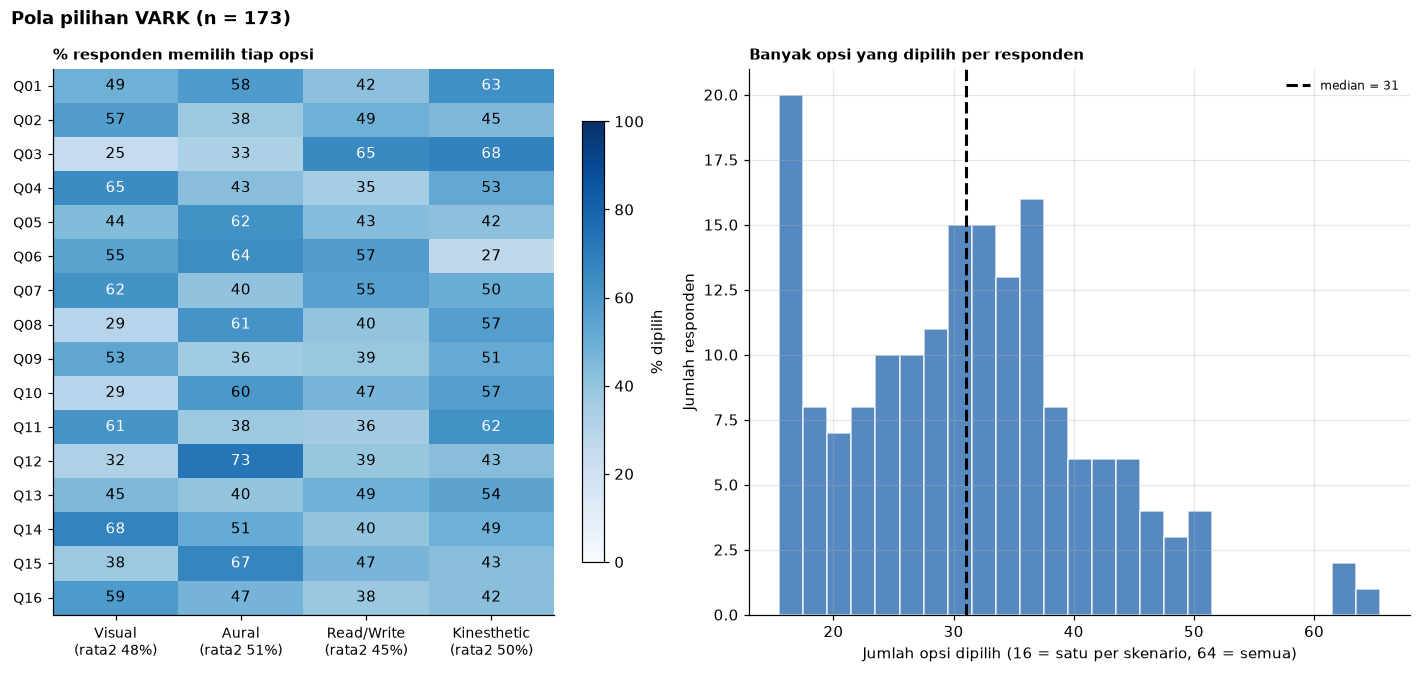

Disimpan: figures_and_outputs\B3_3_pola_fitur_vark.png


In [18]:
NAMA_MOD = {"V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
persen = df_reg[FEATURE_COLS].mean() * 100                       # % responden memilih tiap opsi
grid = pd.DataFrame([[persen[f"VARK_Q{q:02d}_{m}"] for m in MODALITAS] for q in range(1, 17)],
                    index=[f"Q{q:02d}" for q in range(1, 17)], columns=[NAMA_MOD[m] for m in MODALITAS])

ringkas_mod = pd.DataFrame({
    "rata-rata % dipilih": grid.mean(),
    "skenario terendah": [f"{grid[c].idxmin()} ({grid[c].min():.0f}%)" for c in grid],
    "skenario tertinggi": [f"{grid[c].idxmax()} ({grid[c].max():.0f}%)" for c in grid],
}).round(1)
display(ringkas_mod)

jumlah_opsi = df_reg[FEATURE_COLS].sum(axis=1)                    # hanya untuk EDA, bukan fitur
print(f"Jumlah opsi dipilih per responden (dari 64): min {jumlah_opsi.min()}, median {jumlah_opsi.median():.0f}, "
      f"max {jumlah_opsi.max()}; tepat 1 opsi per skenario (= 16): {(jumlah_opsi == 16).sum()} orang")
print(f"Opsi paling jarang : {persen.idxmin()} ({persen.min():.0f}%) | paling sering: {persen.idxmax()} ({persen.max():.0f}%)")
print(f"Opsi dipilih < 10% atau > 90% responden: {int(((persen < 10) | (persen > 90)).sum())} dari 64")
simpan_tabel(grid.round(1), "B3_3_persen_opsi_dipilih")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.2]})
im = ax1.imshow(grid.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10, color="white" if v > 60 else "black")
ax1.set_xticks(range(4), [f"{c}\n(rata2 {grid[c].mean():.0f}%)" for c in grid.columns], fontsize=9)
ax1.set_yticks(range(16), grid.index, fontsize=9)
ax1.grid(False)
ax1.set_title("% responden memilih tiap opsi", loc="left", fontsize=10, fontweight="bold")
fig.colorbar(im, ax=ax1, fraction=0.04, label="% dipilih")

ax2.hist(jumlah_opsi, bins=np.arange(15.5, 66, 2), color=BIRU, alpha=0.8, edgecolor="white")
ax2.axvline(jumlah_opsi.median(), color="black", ls="--", lw=2, label=f"median = {jumlah_opsi.median():.0f}")
ax2.set_xlabel("Jumlah opsi dipilih (16 = satu per skenario, 64 = semua)")
ax2.set_ylabel("Jumlah responden")
ax2.set_title("Banyak opsi yang dipilih per responden", loc="left", fontsize=10, fontweight="bold")
ax2.legend(frameon=False, fontsize=8)
fig.suptitle(f"Pola pilihan VARK (n = {len(df_reg)})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B3_3_pola_fitur_vark")

**Interpretasi B3.3**

**Grafik kiri (heatmap): opsi apa yang dipilih?**
Angka di setiap kotak = persentase dari 173 responden yang mencentang opsi itu. Contoh: baris Q03, kolom Kinesthetic = 68, artinya 68% responden memilih "berlatih soal/mencoba contoh" ketika mengingat materi menjelang ujian. Karena satu skenario boleh dijawab lebih dari satu opsi, jumlah satu baris bisa lebih dari 100%.
- Setiap opsi dipilih oleh **25%–73%** responden. Tidak ada opsi yang hampir tidak pernah atau hampir selalu dipilih (0 opsi di bawah 10% atau di atas 90%).
- Rata-rata per modalitas mirip (Read/Write 45%, Visual 48%, Kinesthetic 50%, Aural 51%), jadi **tidak ada modalitas yang mendominasi**. Pilihan lebih bergantung pada **situasinya**: Q03 (mengingat materi menjelang ujian) didominasi Kinesthetic 68% dan Read/Write 65%, tetapi Visual hanya 25%; Q12 (memastikan benar-benar paham) didominasi Aural 73%.

**Grafik kanan (histogram): berapa banyak opsi yang dipilih tiap orang?**
Untuk setiap responden dihitung total opsi yang dicentang dari 16 skenario. Nilai **16** berarti selalu memilih 1 opsi per skenario, nilai **64** berarti selalu memilih keempat opsi. Tinggi batang = jumlah orang dengan total tersebut.
- Kebanyakan orang memilih **sekitar 2 opsi per skenario** (median 31; 31 ÷ 16 ≈ 1,9).
- Batang paling kiri tinggi: ada kelompok "pemilih tegas", yaitu **18 orang** yang selalu memilih tepat 1 opsi.
- Di ujung kanan ada **3 orang** yang memilih ≥ 60 opsi (ID 55, 125, 132). Ketiganya juga straightliner di skala 1–5, jadi kemungkinan mengisi tanpa banyak membedakan. Mereka tetap dipertahankan (alasan di B2.5).

**Artinya:**
- Setiap fitur punya variasi yang cukup, jadi tidak ada fitur yang "kosong informasi".
- Banyaknya angka 1 di X tidak hanya mencerminkan preferensi belajar, tetapi juga **gaya mengisi survei**: ada yang hemat memilih, ada yang memilih hampir semua. Ini salah satu alasan fitur VARK sulit dipakai untuk menebak IPK.

**Dampak ke modeling:** seluruh 64 fitur dipakai sesuai panduan. Semua fitur sudah berskala sama (0/1), jadi Random Forest tidak memerlukan scaling. Scaling di pipeline Linear Regression hanya agar besar koefisiennya bisa dibandingkan.

## B3.4 Hubungan fitur dengan IPK
Pertanyaan: **apakah memilih opsi tertentu berkaitan dengan IPK yang lebih tinggi atau lebih rendah?**

Metode: korelasi **Spearman** antara setiap indikator (0/1) dan IPK. Spearman dipakai karena IPK menceng kiri dan punya nilai ekstrem. Untuk fitur biner, Spearman setara dengan korelasi point-biserial yang dihitung pada *peringkat* IPK (berkaitan dengan uji Mann–Whitney), sehingga tidak didominasi beberapa IPK sangat rendah. Karena ada 64 uji sekaligus, p-value dikoreksi dengan **FDR (Benjamini–Hochberg)**, seperti di UTS. Tanpa koreksi, sekitar 3 dari 64 uji diperkirakan "signifikan" hanya karena kebetulan.

**Penting:** hasil bagian ini hanya untuk memahami data. Fitur **tidak** dipilih atau dibuang berdasarkan korelasi ini.

|rho| maksimum : 0.20 (VARK_Q01_A)
p < 0,05 (tanpa koreksi): 5 dari 64 | diharapkan karena kebetulan: 3.2
q < 0,05 (setelah FDR)  : 0 dari 64


,rho,p,q_FDR,IPK median dipilih,IPK median tidak dipilih
fitur,,,,,
VARK_Q01_A,0.198,0.009,0.343,3.520,3.300
VARK_Q14_A,0.194,0.011,0.343,3.520,3.400
VARK_Q16_A,0.178,0.019,0.414,3.540,3.360
VARK_Q04_A,0.161,0.035,0.461,3.515,3.340
VARK_Q09_R,-0.154,0.043,0.461,3.360,3.475


Disimpan: figures_and_outputs\B3_4_korelasi_fitur_ipk.csv


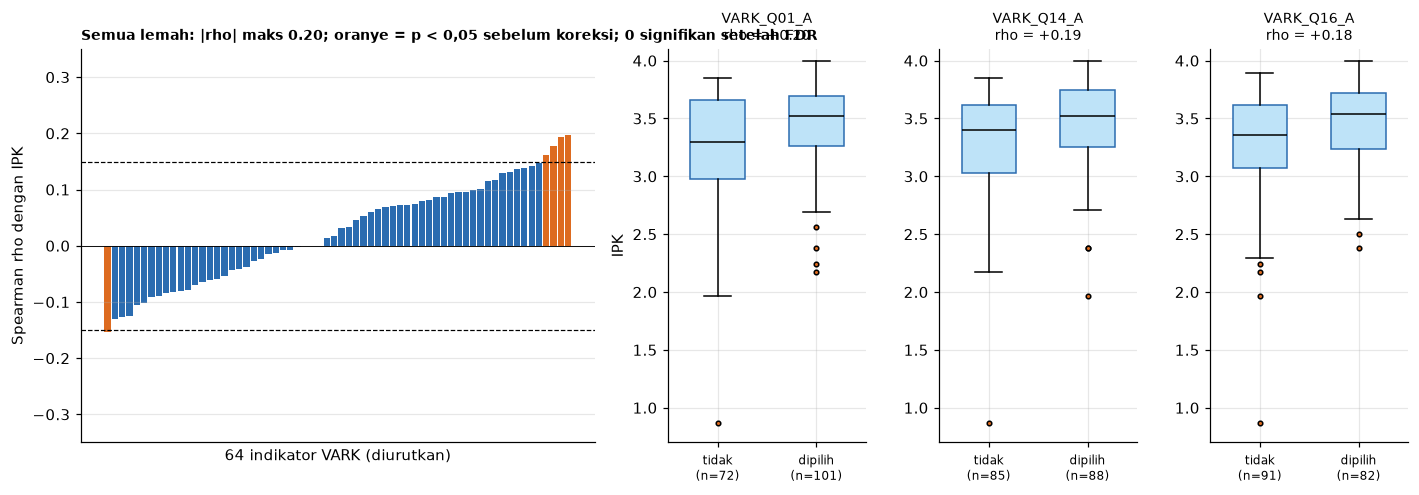

Disimpan: figures_and_outputs\B3_4_hubungan_fitur_ipk.png


In [19]:
kor = pd.DataFrame([(c, *stats.spearmanr(df_reg[c], df_reg[TARGET])) for c in FEATURE_COLS],
                   columns=["fitur", "rho", "p"]).set_index("fitur")
kor["q_FDR"] = stats.false_discovery_control(kor["p"])
kor["IPK median dipilih"] = [df_reg.loc[df_reg[c] == 1, TARGET].median() for c in kor.index]
kor["IPK median tidak dipilih"] = [df_reg.loc[df_reg[c] == 0, TARGET].median() for c in kor.index]
kor = kor.reindex(kor["rho"].abs().sort_values(ascending=False).index)

print(f"|rho| maksimum : {kor['rho'].abs().max():.2f} ({kor.index[0]})")
print(f"p < 0,05 (tanpa koreksi): {int((kor['p'] < 0.05).sum())} dari 64 | diharapkan karena kebetulan: {0.05 * 64:.1f}")
print(f"q < 0,05 (setelah FDR)  : {int((kor['q_FDR'] < 0.05).sum())} dari 64")
display(kor.head(5).round(3))
simpan_tabel(kor.round(4), "B3_4_korelasi_fitur_ipk")

top3 = kor.index[:3].tolist()
batas_p05 = 1.96 / np.sqrt(len(df_reg) - 1)          # perkiraan |rho| untuk p = 0,05

fig = plt.figure(figsize=(13, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[2.6, 1, 1, 1])
ax = fig.add_subplot(gs[0])
urut = kor.sort_values("rho")
ax.bar(range(64), urut["rho"], color=[ORANYE if p < 0.05 else BIRU for p in urut["p"]], width=0.85)
for y in (batas_p05, -batas_p05):
    ax.axhline(y, color="black", ls="--", lw=0.8)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks([])
ax.set_xlabel("64 indikator VARK (diurutkan)")
ax.set_ylabel("Spearman rho dengan IPK")
ax.set_ylim(-0.35, 0.35)
ax.set_title(f"Semua lemah: |rho| maks {kor['rho'].abs().max():.2f}; oranye = p < 0,05 sebelum koreksi; "
             f"{int((kor['q_FDR'] < 0.05).sum())} signifikan setelah FDR", loc="left", fontsize=9, fontweight="bold")

for k, c in enumerate(top3):
    axb = fig.add_subplot(gs[k + 1])
    data = [df_reg.loc[df_reg[c] == 0, TARGET], df_reg.loc[df_reg[c] == 1, TARGET]]
    axb.boxplot(data, widths=0.55, patch_artist=True, boxprops=dict(facecolor="#bee3f8", color=BIRU),
                medianprops=dict(color="black"), flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANYE))
    axb.set_xticks([1, 2], [f"tidak\n(n={len(data[0])})", f"dipilih\n(n={len(data[1])})"], fontsize=8)
    axb.set_ylim(0.7, 4.1)
    axb.set_title(f"{c}\nrho = {kor.loc[c, 'rho']:+.2f}", fontsize=9)
    if k == 0:
        axb.set_ylabel("IPK")
fig.tight_layout()
simpan_fig(fig, "B3_4_hubungan_fitur_ipk")

**Interpretasi B3.4**
- **Yang terlihat:**
  - **Semua hubungan lemah.** Korelasi terbesar hanya 0,20 (`VARK_Q01_A`). Sebagai gambaran, ρ = 0,20 berarti fitur itu hanya berkaitan dengan sekitar 4% (0,20²) variasi peringkat IPK.
  - Ada 5 dari 64 fitur dengan p < 0,05, padahal **karena kebetulan saja** sudah diharapkan sekitar 3 (5% × 64). Setelah koreksi FDR, **0 yang signifikan**. Jadi "sinyal" ini tidak bisa dibedakan dari kebetulan.
  - Ada pola kecil yang menarik: 4 dari 5 fitur teratas adalah opsi **Aural** (Q01, Q14, Q16, Q04). Mahasiswa yang memilih opsi "mendengar/berdiskusi" punya median IPK sekitar 0,1–0,2 poin lebih tinggi. Namun di boxplot, kotak (50% data tengah) kedua kelompok **sangat tumpang tindih**, jadi bedanya kecil dibanding sebaran IPK.
- **Artinya:** memilih opsi VARK tertentu hampir tidak memberi petunjuk tentang IPK seseorang. Pola Aural pun hanya kecenderungan lemah dan **bukan sebab-akibat**.
- **Dampak ke modeling:**
  - R² model diperkirakan **mendekati 0, bahkan bisa negatif**. Itu hasil yang sah selama prosesnya benar, dan rubrik menilai proses serta interpretasi, bukan besar R².
  - **Baseline** (menebak rata-rata) wajib ada sebagai pembanding di B5.
  - Fitur tidak dipilih berdasarkan korelasi ini (menghindari leakage); seluruh 64 fitur tetap dipakai.

## B3.5 Korelasi antar-fitur (cek multikolinearitas)
Pertanyaan: **apakah ke-64 fitur saling tumpang-tindih?** Kalau banyak fitur saling berkorelasi kuat (multikolinearitas), koefisien Linear Regression menjadi tidak stabil. Ukuran yang dipakai:
- korelasi antar-fitur (heatmap diurutkan per modalitas), dan
- **VIF** (*Variance Inflation Factor*): seberapa besar satu fitur bisa ditebak dari 63 fitur lainnya. Patokan umum: VIF > 5 perlu diwaspadai, > 10 bermasalah.

Bagian ini tidak melibatkan IPK sama sekali, sehingga aman dihitung sebelum split. Hasilnya hanya deskriptif.

,nilai
jumlah pasangan fitur,2016.00
rata-rata |r|,0.12
|r| maksimum,0.51
"pasangan dengan |r| > 0,5",2.00
"r rata-rata: modalitas sama, skenario beda",0.24
r rata-rata: opsi dalam skenario yang sama,-0.07
VIF median,2.48
VIF maksimum,3.52
fitur dengan VIF > 5,0.00


Disimpan: figures_and_outputs\B3_5_korelasi_antar_fitur.csv
Rata-rata korelasi per blok modalitas:


,Visual,Aural,Read/Write,Kinesthetic
Visual,0.29,0.02,0.04,0.06
Aural,0.02,0.19,0.08,-0.00
Read/Write,0.04,0.08,0.21,0.06
Kinesthetic,0.06,-0.00,0.06,0.29


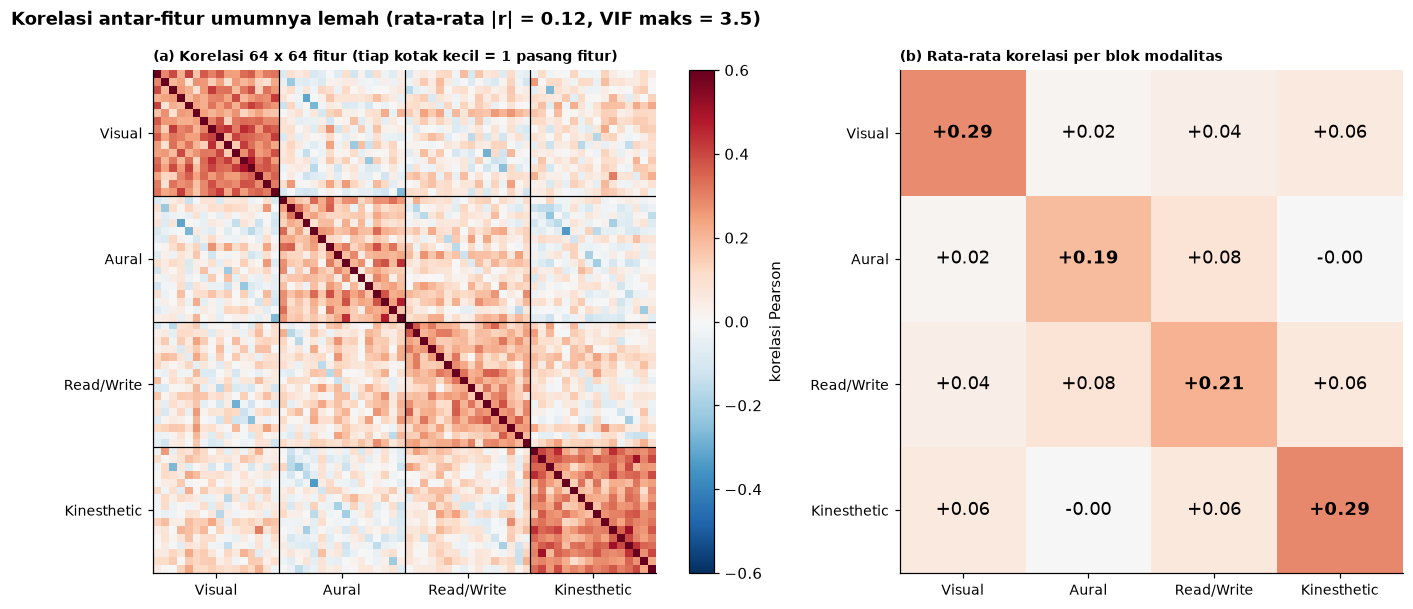

Disimpan: figures_and_outputs\B3_5_korelasi_antar_fitur.png


In [20]:
URUT_MOD = [f"VARK_Q{q:02d}_{m}" for m in MODALITAS for q in range(1, 17)]   # dikelompokkan per modalitas
korX = df_reg[URUT_MOD].corr()
iu = np.triu_indices(64, k=1)
nilai_r = korX.values[iu]
mod_i = np.array([c[-1] for c in URUT_MOD])
skn_i = np.array([c[6:8] for c in URUT_MOD])
sama_mod = (mod_i[iu[0]] == mod_i[iu[1]]) & (skn_i[iu[0]] != skn_i[iu[1]])
sama_skn = skn_i[iu[0]] == skn_i[iu[1]]

vif = pd.Series(np.diag(np.linalg.inv(korX.values)), index=URUT_MOD)   # VIF_j = diagonal invers matriks korelasi

ringkas_kor = pd.Series({
    "jumlah pasangan fitur": len(nilai_r),
    "rata-rata |r|": np.abs(nilai_r).mean(),
    "|r| maksimum": np.abs(nilai_r).max(),
    "pasangan dengan |r| > 0,5": int((np.abs(nilai_r) > 0.5).sum()),
    "r rata-rata: modalitas sama, skenario beda": nilai_r[sama_mod].mean(),
    "r rata-rata: opsi dalam skenario yang sama": nilai_r[sama_skn].mean(),
    "VIF median": vif.median(),
    "VIF maksimum": vif.max(),
    "fitur dengan VIF > 5": int((vif > 5).sum()),
}).round(2).to_frame("nilai")
display(ringkas_kor)
simpan_tabel(ringkas_kor, "B3_5_korelasi_antar_fitur")

# Ringkasan per blok modalitas: rata-rata korelasi antar-fitur (diagonal: modalitas sama, skenario berbeda)
nama4 = [NAMA_MOD[m] for m in MODALITAS]
blok = pd.DataFrame(index=nama4, columns=nama4, dtype=float)
for a in range(4):
    for b in range(4):
        sub = korX.values[16 * a:16 * (a + 1), 16 * b:16 * (b + 1)]
        blok.iloc[a, b] = sub[~np.eye(16, dtype=bool)].mean() if a == b else sub.mean()
print("Rata-rata korelasi per blok modalitas:")
display(blok.round(2))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax.imshow(korX.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
for b in range(1, 4):
    ax.axhline(b * 16 - 0.5, color="black", lw=0.8)
    ax.axvline(b * 16 - 0.5, color="black", lw=0.8)
pos = [7.5 + 16 * k for k in range(4)]
ax.set_xticks(pos, nama4, fontsize=9)
ax.set_yticks(pos, nama4, fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="korelasi Pearson")
ax.set_title("(a) Korelasi 64 x 64 fitur (tiap kotak kecil = 1 pasang fitur)", loc="left", fontsize=9, fontweight="bold")

im2 = ax2.imshow(blok.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
for a in range(4):
    for b in range(4):
        ax2.text(b, a, f"{blok.values[a, b]:+.2f}", ha="center", va="center", fontsize=12,
                 fontweight="bold" if a == b else "normal")
ax2.set_xticks(range(4), nama4, fontsize=9)
ax2.set_yticks(range(4), nama4, fontsize=9)
ax2.grid(False)
ax2.set_title("(b) Rata-rata korelasi per blok modalitas", loc="left", fontsize=9, fontweight="bold")
fig.suptitle(f"Korelasi antar-fitur umumnya lemah (rata-rata |r| = {np.abs(nilai_r).mean():.2f}, VIF maks = {vif.max():.1f})",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B3_5_korelasi_antar_fitur")

**Interpretasi B3.5**

**Cara membaca grafik:**
- **Grafik (a)** berisi 64 × 64 kotak kecil; tiap kotak adalah korelasi satu pasang fitur. Merah = sering dipilih bersamaan, biru = jarang dipilih bersamaan, putih = tidak berhubungan. Fitur diurutkan per modalitas (16 skenario Visual, lalu Aural, dst.), sehingga terbentuk 4 kotak besar. Grafik ini terlalu padat untuk diberi angka.
- **Grafik (b)** meringkas grafik (a) menjadi 4 × 4: setiap angka adalah **rata-rata korelasi** di satu kotak besar.

**Yang terlihat:**
- Fitur umumnya **tidak saling tumpang tindih**: rata-rata |r| = 0,12, maksimum 0,51, dan hanya 2 dari 2.016 pasangan yang |r| > 0,5. **VIF maksimum 3,5**, masih di bawah batas waspada 5.
- **Diagonal grafik (b)** bernilai +0,19 sampai +0,29: orang yang memilih opsi Visual di satu skenario cenderung memilih Visual juga di skenario lain, begitu pula modalitas lain. Ini wajar dan menunjukkan jawaban responden cukup konsisten.
- **Di luar diagonal** nilainya hampir 0 (−0,00 sampai +0,08): memilih satu modalitas tidak membuat orang lebih atau kurang memilih modalitas lain.

**Artinya:** multikolinearitas **ringan**, jadi bukan masalah utama untuk Linear Regression.

**Dampak ke modeling:** risiko overfit Linear Regression lebih disebabkan **jumlah fitur yang banyak dibanding jumlah data**: 64 fitur (+1 intercept) untuk sekitar 138 baris training, atau hampir 1 parameter untuk setiap 2 data. Dengan perbandingan seperti itu, model bisa "menghafal" data training tetapi gagal di data baru. Dugaan ini akan dibuktikan di B5 dengan membandingkan error training dan error cross-validation.

## B3.6 Kesimpulan EDA: apa yang kami pelajari dan apa artinya untuk modeling

**Ringkasnya:** datanya sudah bersih dan siap dipakai (173 mahasiswa, 64 fitur, tanpa nilai kosong). Namun, jawaban VARK hampir tidak berhubungan dengan IPK. Jadi kami **tidak berharap model bisa menebak IPK dengan akurat**. Tujuan modeling adalah menguji hal itu secara adil: apakah Linear Regression dan Random Forest bisa lebih baik daripada tebakan paling sederhana, yaitu menebak rata-rata IPK.

| # | Yang kami temukan | Jadi, di tahap modeling kami... |
|---|---|---|
| 1 | 19 mahasiswa tanpa IPK sudah dikeluarkan, dan tidak ada fitur yang kosong (B3.1) | memakai 173 baris dan tidak perlu mengisi data kosong (imputasi) |
| 2 | Kebanyakan IPK tinggi (82% ≥ 3,00); IPK rendah hanya sedikit, termasuk 8 nilai ekstrem (B3.2) | memakai **MAE** sebagai ukuran utama karena mudah dibaca ("rata-rata tebakan meleset berapa poin IPK"), ditambah RMSE dan R². Kami juga mengecek apakah error terbesar ada di IPK rendah (B6). Skala IPK tidak diubah |
| 3 | Semua 64 opsi cukup bervariasi dan nilainya 0/1; banyaknya opsi yang dipilih juga dipengaruhi gaya mengisi survei (B3.3) | memakai semua 64 fitur; scaling hanya untuk Linear Regression |
| 4 | Tidak ada opsi yang berhubungan nyata dengan IPK: korelasi paling besar 0,20 dan 0 yang signifikan setelah koreksi (B3.4) | membandingkan setiap model dengan **baseline "tebak rata-rata"**. R² sekitar 0 atau negatif kami anggap hasil yang wajar, bukan kesalahan |
| 5 | Fitur tidak saling tumpang tindih (VIF maks 3,5), tetapi jumlahnya banyak (64) dibanding data training (±138) (B3.5) | mewaspadai Linear Regression yang "menghafal" data training, dan membuktikannya dengan membandingkan error training vs cross-validation (B5) |
| 6 | Sinyalnya lemah dan datanya sedikit | membatasi Random Forest supaya tidak menghafal: setiap daun pohon minimal berisi beberapa data (`min_samples_leaf`), dipilih lewat GridSearchCV |
| 7 | Data test hanya ±35 baris, sehingga angkanya mudah berubah | memilih model dari cross-validation di data training; data test hanya dipakai **sekali** di akhir (B6) |

### Checkpoint: data siap untuk modeling
Sel ini hanya memastikan bahan untuk B4 sudah lengkap: **X** (173 × 64), **y** (173 IPK), tanpa nilai kosong, dan `ID` disimpan terpisah (bukan fitur) untuk menelusuri error di B6. Pembagian train/test baru dilakukan di B4.

In [21]:
X = df_reg[FEATURE_COLS]
y = df_reg[TARGET]
id_reg = df_reg["ID"]          # hanya untuk menelusuri error di B6, bukan fitur

assert X.shape == (173, 64) and y.shape == (173,)
assert not X.isna().any().any() and not y.isna().any()
assert list(X.columns) == FEATURE_COLS and "ID" not in X.columns
print(f"X: {X.shape} | y: {y.shape} | IPK {y.min():.2f}-{y.max():.2f} | ID unik: {id_reg.is_unique}")
print("Data siap masuk B4 (split & pipeline).")

X: (173, 64) | y: (173,) | IPK 0.87-4.00 | ID unik: True
Data siap masuk B4 (split & pipeline).


---
# B4 – Pembagian data & pipeline

Bagian ini menyiapkan aturan yang adil untuk semua model sebelum training dimulai. Tiga aturan dari spesifikasi yang dijaga:

| Aturan | Cara memenuhinya |
|---|---|
| Train : test = 80 : 20 dengan `random_state = 42` | `train_test_split(test_size=TEST_SIZE, random_state=SEED)` |
| Split dibuat **sebelum** transformasi yang belajar dari data (scaling, imputasi, seleksi fitur) | Split dilakukan di sini, dan scaling baru terjadi **di dalam pipeline** saat model di-fit |
| Kedua model memakai pembagian data yang **sama** | Satu `X_train`/`X_test` dan satu skema cross-validation (`cv`) untuk semua model |

## B4.1 Membagi data train dan test
Data test (20%) **disimpan dan tidak disentuh** sampai evaluasi akhir di B6. Semua pemilihan model dan parameter di B5 hanya memakai data train.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
id_train, id_test = id_reg.loc[X_train.index], id_reg.loc[X_test.index]   # ID hanya untuk analisis error

# Pengaman: ukuran benar, tidak ada baris yang masuk ke dua bagian sekaligus
assert len(X_train) + len(X_test) == len(X) == 173
assert set(X_train.index).isdisjoint(X_test.index)
assert list(X_train.columns) == list(X_test.columns) == FEATURE_COLS

print(f"Train: {X_train.shape[0]} baris ({len(X_train) / len(X):.0%}) | Test: {X_test.shape[0]} baris ({len(X_test) / len(X):.0%})")
print(f"Jumlah fitur: {X_train.shape[1]} | random_state = {SEED}")

# Simpan daftar ID per bagian agar pembagian bisa diperiksa ulang
pembagian = pd.concat([pd.DataFrame({"ID": id_train.values, "bagian": "train"}),
                       pd.DataFrame({"ID": id_test.values, "bagian": "test"})]).sort_values("ID").set_index("ID")
simpan_tabel(pembagian, "B4_1_pembagian_train_test")

Train: 138 baris (80%) | Test: 35 baris (20%)
Jumlah fitur: 64 | random_state = 42
Disimpan: figures_and_outputs\B4_1_pembagian_train_test.csv


## B4.2 Apakah data train dan test mirip?
Untuk regresi, spesifikasi tidak mewajibkan stratifikasi (stratifikasi biasanya untuk target kategori). Yang perlu dipastikan adalah **data test mewakili data train**: sebaran IPK-nya mirip dan IPK rendah ikut masuk ke test. Kalau test hanya berisi IPK tinggi, hasil evaluasi di B6 akan terlihat lebih bagus dari kenyataannya.

Yang dibandingkan:
- statistik IPK (rata-rata, median, simpangan baku, jumlah IPK ekstrem bawah dari B2.4),
- uji **Kolmogorov–Smirnov** (KS): apakah sebaran IPK train dan test berbeda secara signifikan,
- selisih persentase opsi VARK yang dipilih di train dan test (64 fitur).

,Train,Test,Semua (173)
n,138.00,35.00,173.00
rata-rata,3.36,3.37,3.36
median,3.42,3.46,3.42
simpangan baku,0.45,0.45,0.45
min,0.87,2.24,0.87
max,4.00,3.99,4.00
"% IPK >= 3,50",45.65,45.71,45.66
IPK ekstrem (< 2.47),6.00,2.00,8.00


Disimpan: figures_and_outputs\B4_2_banding_train_test.csv
Uji KS sebaran IPK train vs test: statistik = 0.114, p = 0.811
Selisih % opsi dipilih (train vs test): rata-rata 6.1 poin, maksimum 17.3 poin (VARK_Q08_K)


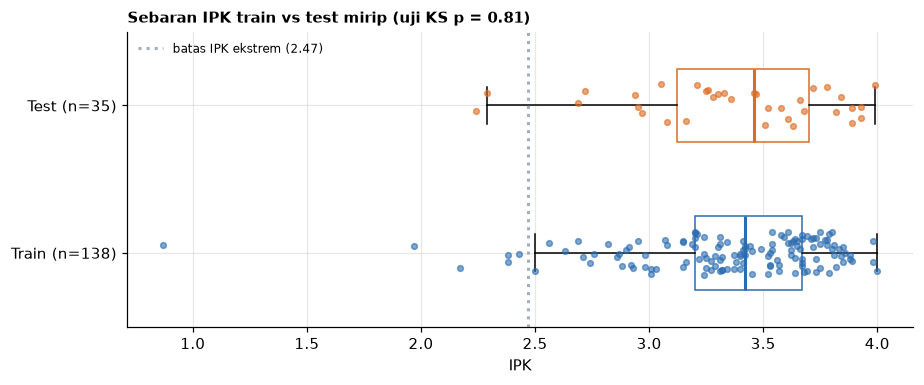

Disimpan: figures_and_outputs\B4_2_sebaran_ipk_train_test.png


In [23]:
def ringkas_bagian(nilai_ipk):
    return pd.Series({
        "n": len(nilai_ipk), "rata-rata": nilai_ipk.mean(), "median": nilai_ipk.median(),
        "simpangan baku": nilai_ipk.std(), "min": nilai_ipk.min(), "max": nilai_ipk.max(),
        "% IPK >= 3,50": (nilai_ipk >= 3.5).mean() * 100,
        f"IPK ekstrem (< {batas_bawah:.2f})": int((nilai_ipk < batas_bawah).sum()),
    })

banding = pd.DataFrame({"Train": ringkas_bagian(y_train), "Test": ringkas_bagian(y_test),
                        "Semua (173)": ringkas_bagian(y)}).round(2)
display(banding)
simpan_tabel(banding, "B4_2_banding_train_test")

ks = stats.ks_2samp(y_train, y_test)
selisih_fitur = (X_train.mean() - X_test.mean()).abs() * 100
print(f"Uji KS sebaran IPK train vs test: statistik = {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
print(f"Selisih % opsi dipilih (train vs test): rata-rata {selisih_fitur.mean():.1f} poin, "
      f"maksimum {selisih_fitur.max():.1f} poin ({selisih_fitur.idxmax()})")

# Grafik: sebaran IPK train vs test
fig, ax = plt.subplots(figsize=(8.5, 3.6))
bagian = [("Train", y_train, BIRU), ("Test", y_test, ORANYE)]
for pos, (nama, nilai, warna) in enumerate(bagian, start=1):
    ax.boxplot(nilai, positions=[pos], widths=0.5, showfliers=False, **ARAH_HORIZONTAL,
               patch_artist=True, boxprops=dict(facecolor="white", color=warna), medianprops=dict(color=warna, lw=2))
    jitter = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(nilai))
    ax.scatter(nilai, pos + jitter, s=14, color=warna, alpha=0.6, zorder=3)
ax.axvline(batas_bawah, color=ABU, ls=":", lw=2, label=f"batas IPK ekstrem ({batas_bawah:.2f})")
ax.set_yticks([1, 2], [f"Train (n={len(y_train)})", f"Test (n={len(y_test)})"])
ax.set_xlabel("IPK")
ax.set_title(f"Sebaran IPK train vs test mirip (uji KS p = {ks.pvalue:.2f})", loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
simpan_fig(fig, "B4_2_sebaran_ipk_train_test")

**Interpretasi B4.2**
- **Yang terlihat:** rata-rata, median, dan simpangan baku IPK train dan test hampir sama (3,36 vs 3,37; 3,42 vs 3,46; 0,45 vs 0,45). Uji KS memberi p = 0,81, artinya **tidak ada perbedaan sebaran yang berarti**. Persentase opsi VARK yang dipilih rata-rata hanya berbeda 6 poin. Selisih terbesar (17 poin, `VARK_Q08_K`) masih wajar untuk test sebesar 35 orang, karena satu orang saja sudah bernilai ±3 poin persen.
- **Catatan penting:** 2 dari 8 IPK ekstrem masuk test (2,24 dan 2,29), tetapi **3 IPK paling rendah (0,87; 1,97; 2,17) semuanya ada di train**. Akibatnya, test tidak memuat kasus yang paling sulit ditebak, sehingga error di test **bisa terlihat sedikit lebih kecil** daripada di cross-validation. Hal ini akan diingat saat membaca hasil di B6.
- **Kesimpulan:** pembagian acak dengan `random_state = 42` sudah cukup mewakili, jadi **stratifikasi tidak diperlukan**. Pembagian ini dipakai apa adanya dan tidak diulang dengan seed lain, karena memilih seed berdasarkan hasil juga termasuk mengintip data test.

## B4.3 Pipeline model dan skema cross-validation
Setiap model dibungkus dalam `Pipeline`. Keuntungannya:
- langkah yang **belajar dari data** (di sini: `StandardScaler` yang menghitung rata-rata dan simpangan baku) selalu di-fit **hanya pada data training**, termasuk di setiap lipatan cross-validation. Jadi tidak ada informasi data validasi/test yang bocor;
- model yang disimpan di B7 sudah membawa preprocessing-nya sendiri, sehingga aplikasi Streamlit cukup memberi 64 fitur mentah (0/1).

| Model | Isi pipeline | Kenapa |
|---|---|---|
| **Baseline** | `DummyRegressor(strategy="mean")` | Selalu menebak rata-rata IPK training. Patokan minimum: model lain baru berguna kalau lebih baik dari ini |
| **Linear Regression** | `StandardScaler` → `LinearRegression` | Model wajib. Scaling tidak mengubah prediksi OLS, tetapi membuat besar koefisien bisa dibandingkan |
| **Random Forest Regressor** | `RandomForestRegressor(n_estimators=500, random_state=42)` | Model wajib. Pohon keputusan tidak terpengaruh skala fitur, jadi tidak perlu scaler. Parameter pembatas pohon (`min_samples_leaf`, `max_features`, `max_depth`) dipilih di B5 |

**Skema cross-validation (CV):** data train (138 baris) dibagi menjadi 5 lipatan. Model dilatih di 4 lipatan dan diuji di 1 lipatan sisanya, bergantian 5 kali. Objek `cv` yang **sama** (`shuffle=True`, `random_state=42`) dipakai untuk semua model dan untuk GridSearch, sehingga setiap model diuji pada potongan data yang persis sama.

**Metrik:** MAE (utama), RMSE, dan R², sesuai keputusan di B3.6.

In [24]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

PIPELINES = {
    "Baseline (rata-rata)": Pipeline([("model", DummyRegressor(strategy="mean"))]),
    "Linear Regression":    Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Random Forest":        Pipeline([("model", RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1))]),
}

# Metrik untuk cross_validate & GridSearch (sklearn memakai tanda negatif untuk error -> dibalik saat ditampilkan)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

# Ringkasan pipeline
display(pd.DataFrame({
    "langkah": [" -> ".join(type(step).__name__ for _, step in p.steps) for p in PIPELINES.values()],
    "preprocessing yang belajar dari data": ["-", "StandardScaler (di-fit hanya pada data latih)", "-"],
}, index=PIPELINES.keys()))

# Ukuran setiap lipatan CV
lipatan = pd.DataFrame([(k + 1, len(tr), len(va)) for k, (tr, va) in enumerate(cv.split(X_train))],
                       columns=["lipatan", "n_latih", "n_validasi"]).set_index("lipatan")
display(lipatan.T)
assert lipatan["n_validasi"].sum() == len(X_train)   # setiap baris train jadi data validasi tepat sekali

,langkah,preprocessing yang belajar dari data
Baseline (rata-rata),DummyRegressor,-
Linear Regression,StandardScaler -> LinearRegression,StandardScaler (di-fit hanya pada data latih)
Random Forest,RandomForestRegressor,-


lipatan,1,2,3,4,5
n_latih,110,110,110,111,111
n_validasi,28,28,28,27,27


**Ringkasan B4:**
- Data dibagi **138 train : 35 test** (80 : 20, `random_state = 42`). Test disimpan untuk evaluasi akhir di B6.
- Sebaran IPK dan pola pilihan VARK di train dan test **mirip**, jadi split tanpa stratifikasi sudah representatif (B4.2).
- Tiga pipeline siap: **Baseline**, **Linear Regression** (dengan scaler di dalam pipeline), dan **Random Forest**.
- Semua model memakai split dan skema CV yang **sama** (5 lipatan, 110–111 baris latih dan 27–28 baris validasi per lipatan). Tidak ada transformasi yang di-fit di luar data training, sehingga bebas *data leakage*.

---
# B5 – Training & pemilihan model

Semua langkah di bagian ini **hanya memakai data train (138 baris)** dengan cross-validation 5 lipatan (`cv` dari B4). Data test belum disentuh.

**Urutan kerja:**
1. **B5.1** Baseline dan Linear Regression: dilatih apa adanya (OLS tidak punya hyperparameter yang berarti).
2. **B5.2** Random Forest: hyperparameter dipilih dengan `GridSearchCV` di data train.
3. **B5.3** *(opsional)* Ridge Regression: Linear Regression dengan regularisasi, untuk menguji penyebab masalah LR.
4. **B5.4** *(opsional)* Uji permutasi: apakah model benar-benar menangkap sinyal, atau hanya kebetulan?
5. **B5.5** Tabel perbandingan semua model.
6. **B5.6** Pemilihan model yang dibawa ke evaluasi test.

**Aturan pemilihan (ditetapkan sebelum melihat hasil):** dari dua model wajib (Linear Regression dan Random Forest), dipilih yang **MAE cross-validation-nya paling kecil**. Model opsional (Ridge) hanya pembanding untuk analisis, tidak ikut dipilih. Data test tidak dipakai dalam pemilihan.

**Cara membaca tabel di bagian ini:**
- **MAE/RMSE CV** = error rata-rata pada lipatan validasi (data yang tidak dilihat model saat dilatih). Inilah ukuran kemampuan model pada data baru. Makin kecil makin baik.
- **MAE/R² train** = error pada data yang dipakai untuk melatih. Kalau error train jauh lebih kecil daripada error CV, model **menghafal** data training (*overfitting*).
- **SD** = seberapa besar hasil berubah antar lipatan.

## B5.1 Baseline dan Linear Regression

In [25]:
def evaluasi_cv(nama, model):
    """Cross-validation 5 lipatan di data train; kembalikan ringkasan metrik validasi dan train."""
    h = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    return pd.Series({
        "MAE CV": -h["test_MAE"].mean(), "MAE CV (SD)": h["test_MAE"].std(),
        "RMSE CV": -h["test_RMSE"].mean(), "R2 CV": h["test_R2"].mean(), "R2 CV (SD)": h["test_R2"].std(),
        "MAE train": -h["train_MAE"].mean(), "R2 train": h["train_R2"].mean(),
    }, name=nama)

hasil_cv = pd.DataFrame([evaluasi_cv("Baseline (rata-rata)", PIPELINES["Baseline (rata-rata)"]),
                         evaluasi_cv("Linear Regression", PIPELINES["Linear Regression"])])
display(hasil_cv.round(3))

# Seberapa jauh tebakan LR pada lipatan validasi (data yang tidak dilihat saat dilatih)?
pred_lr_cv = cross_val_predict(PIPELINES["Linear Regression"], X_train, y_train, cv=cv)
print(f"Jumlah parameter LR: {len(FEATURE_COLS) + 1} (64 koefisien + intercept) untuk {len(X_train)} baris train")
print(f"Tebakan LR di lipatan validasi: {pred_lr_cv.min():.2f} s.d. {pred_lr_cv.max():.2f} "
      f"(IPK asli train: {y_train.min():.2f} s.d. {y_train.max():.2f})")
print(f"Tebakan di atas 4,00 (mustahil untuk IPK): {(pred_lr_cv > 4).sum()} dari {len(pred_lr_cv)}")

,MAE CV,MAE CV (SD),RMSE CV,R2 CV,R2 CV (SD),MAE train,R2 train
Baseline (rata-rata),0.336,0.053,0.446,-0.081,0.062,0.328,0.000
Linear Regression,0.507,0.061,0.666,-1.460,0.411,0.194,0.702


Jumlah parameter LR: 65 (64 koefisien + intercept) untuk 138 baris train
Tebakan LR di lipatan validasi: 1.81 s.d. 4.83 (IPK asli train: 0.87 s.d. 4.00)
Tebakan di atas 4,00 (mustahil untuk IPK): 17 dari 138


**Interpretasi B5.1**
- **Baseline** (selalu menebak rata-rata IPK train, 3,36) rata-rata meleset **0,34 poin IPK** (MAE CV 0,336). Inilah patokan yang harus dikalahkan. R² CV-nya sedikit negatif (−0,08). Itu wajar: R² di setiap lipatan dihitung terhadap rata-rata lipatan validasi itu sendiri, sedangkan baseline menebak rata-rata data latih, jadi selisih kecil di antara keduanya membuat R² sedikit di bawah 0.
- **Linear Regression terlihat bagus di data train, tetapi buruk di data baru:**
  - Di data train, R² = **0,70**, seolah-olah model menjelaskan 70% variasi IPK.
  - Di lipatan validasi, R² = **−1,46** dan MAE **0,51**, jauh lebih buruk dari sekadar menebak rata-rata (0,34).
  - Tebakannya melebar dari 1,81 sampai 4,83, dan **17 dari 138 tebakan di atas 4,00**, nilai yang mustahil untuk IPK.
- **Artinya:** Linear Regression **menghafal** data train (*overfitting*), seperti mahasiswa yang menghafal kunci jawaban soal tahun lalu: nilainya sempurna di soal yang sama, tetapi gagal di soal baru. Ini sesuai dugaan di B3.5: 65 parameter untuk hanya 110 baris latih per lipatan memberi model terlalu banyak "kebebasan" untuk menyesuaikan diri dengan noise.
- **Dampak:** LR tetap dilaporkan karena model wajib, dan penyebab overfit-nya diuji lebih lanjut di B5.3 (Ridge).

## B5.2 Random Forest: tuning hyperparameter dengan GridSearchCV
Random Forest dengan setelan default membiarkan setiap pohon tumbuh sampai setiap daun hanya berisi **1 mahasiswa**, sehingga pohon bisa menghafal data. Karena EDA menunjukkan sinyal yang lemah (B3.4), tiga "rem" berikut di-tuning:

| Parameter | Arti sederhana | Nilai yang dicoba |
|---|---|---|
| `min_samples_leaf` | Minimal berapa mahasiswa dalam satu daun (kelompok akhir pohon). Makin besar, makin tidak bisa menghafal | 1 (default), 3, 5, 10, 20 |
| `max_features` | Berapa bagian fitur yang boleh dilihat di setiap percabangan. Makin kecil, pohon makin beragam | `sqrt` (8 fitur), 0.3 (19 fitur), 1.0 (semua, default) |
| `max_depth` | Kedalaman maksimum pohon | None (bebas, default), 5 |

Total **30 kombinasi × 5 lipatan = 150 kali training**, semuanya di data train. Kombinasi dengan MAE CV terkecil dipilih, lalu dilatih ulang di seluruh 138 baris train (`refit`). `n_estimators = 500` dibuat tetap, karena menambah pohon hanya membuat hasil lebih stabil, bukan lebih "pintar".

Jumlah kombinasi dicoba: 30
Parameter terbaik: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 3}


,min_samples_leaf,max_features,max_depth,MAE CV,MAE CV (SD),R2 CV,MAE train
1,3,sqrt,5,0.336,0.043,-0.073,0.221
2,5,sqrt,None,0.336,0.047,-0.069,0.259
3,5,sqrt,5,0.336,0.047,-0.069,0.259
4,3,sqrt,None,0.337,0.043,-0.075,0.218
5,20,sqrt,5,0.337,0.052,-0.080,0.316
6,20,sqrt,None,0.337,0.052,-0.080,0.316
7,10,sqrt,5,0.337,0.051,-0.079,0.294
8,10,sqrt,None,0.337,0.051,-0.079,0.294
9,10,0.3,5,0.338,0.049,-0.086,0.282
10,10,0.3,None,0.338,0.049,-0.086,0.282


Disimpan: figures_and_outputs\B5_2_gridsearch_rf.csv


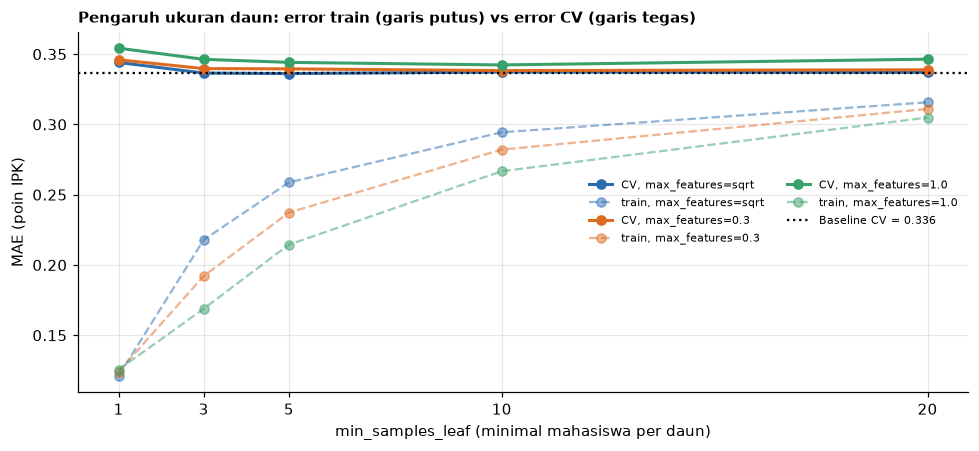

Disimpan: figures_and_outputs\B5_2_tuning_rf.png


In [26]:
GRID_RF = {
    "model__min_samples_leaf": [1, 3, 5, 10, 20],
    "model__max_features": ["sqrt", 0.3, 1.0],
    "model__max_depth": [None, 5],
}
grid_rf = GridSearchCV(PIPELINES["Random Forest"], GRID_RF, cv=cv, scoring=SCORING,
                       refit="MAE", return_train_score=True)
grid_rf.fit(X_train, y_train)

# Tabel semua kombinasi, diurutkan dari MAE CV terkecil
hasil_grid = pd.DataFrame(grid_rf.cv_results_)
tabel_grid = pd.DataFrame({
    "min_samples_leaf": hasil_grid["param_model__min_samples_leaf"],
    "max_features": hasil_grid["param_model__max_features"].map(str),
    "max_depth": hasil_grid["param_model__max_depth"].map(lambda v: "None" if v is None or pd.isna(v) else str(v)),
    "MAE CV": -hasil_grid["mean_test_MAE"], "MAE CV (SD)": hasil_grid["std_test_MAE"],
    "R2 CV": hasil_grid["mean_test_R2"], "MAE train": -hasil_grid["mean_train_MAE"],
}).sort_values("MAE CV").reset_index(drop=True)
tabel_grid.index += 1
print(f"Jumlah kombinasi dicoba: {len(tabel_grid)}")
print("Parameter terbaik:", {k.replace("model__", ""): v for k, v in grid_rf.best_params_.items()})
display(tabel_grid.head(10).round(3))
simpan_tabel(tabel_grid.round(4), "B5_2_gridsearch_rf")

# Grafik: pengaruh min_samples_leaf terhadap error CV vs error train (max_depth = None)
fig, ax = plt.subplots(figsize=(9, 4.2))
for mf, warna in zip(["sqrt", "0.3", "1.0"], [BIRU, ORANYE, "#38a169"]):
    sub = tabel_grid[(tabel_grid["max_features"] == mf) & (tabel_grid["max_depth"] == "None")].sort_values("min_samples_leaf")
    ax.plot(sub["min_samples_leaf"], sub["MAE CV"], "o-", color=warna, lw=2, label=f"CV, max_features={mf}")
    ax.plot(sub["min_samples_leaf"], sub["MAE train"], "o--", color=warna, alpha=0.5, label=f"train, max_features={mf}")
mae_baseline = hasil_cv.loc["Baseline (rata-rata)", "MAE CV"]
ax.axhline(mae_baseline, color="black", ls=":", lw=1.5, label=f"Baseline CV = {mae_baseline:.3f}")
ax.set_xticks(GRID_RF["model__min_samples_leaf"])
ax.set_xlabel("min_samples_leaf (minimal mahasiswa per daun)")
ax.set_ylabel("MAE (poin IPK)")
ax.set_title("Pengaruh ukuran daun: error train (garis putus) vs error CV (garis tegas)", loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=7.5, ncol=2, loc="center right")
fig.tight_layout()
simpan_fig(fig, "B5_2_tuning_rf")

# Tambahkan RF default dan RF hasil tuning ke tabel perbandingan
rf_default = PIPELINES["Random Forest"]   # default sklearn: min_samples_leaf=1, max_features=1.0, max_depth=None
hasil_cv = pd.concat([hasil_cv.T,
                      evaluasi_cv("Random Forest (default)", rf_default),
                      evaluasi_cv("Random Forest (tuning)", grid_rf.best_estimator_)], axis=1).T

**Interpretasi B5.2**
- **Parameter terbaik:** `min_samples_leaf = 3`, `max_features = "sqrt"`, `max_depth = 5`, dengan MAE CV **0,336**. Namun 10 kombinasi teratas hanya berbeda paling banyak 0,002 poin IPK, jauh lebih kecil dari variasi antar lipatan (SD ±0,04–0,05). Jadi kombinasi-kombinasi itu **praktis sama bagusnya**; GridSearch hanya mengambil yang angkanya paling kecil.
- **Grafik menunjukkan efek "rem" dengan jelas:**
  - Dengan `min_samples_leaf = 1` (default), error train sangat kecil (**0,12**) tetapi error CV paling besar (**0,344–0,354**). Ini tanda RF menghafal.
  - Begitu daun diperbesar, error train naik (sampai ±0,31) dan error CV turun ke sekitar **0,336**, yaitu **sama dengan baseline** (garis titik-titik).
  - `max_features = "sqrt"` (garis biru) sedikit lebih baik daripada memakai semua fitur (garis hijau): pohon yang lebih beragam sedikit lebih tahan terhadap noise.
- **Artinya:** "rem" membuat RF berhenti menghafal, tetapi yang tersisa hanyalah tebakan yang hampir sama dengan rata-rata. RF default (MAE CV 0,354, R² −0,15) lebih buruk dari baseline, dan RF hasil tuning (MAE CV 0,336, R² −0,07) hanya menyamai baseline.
- **Catatan:** skor terbaik GridSearch sedikit terlalu optimis karena dipilih dari 30 percobaan. Karena itu angka akhirnya tetap diukur ulang di data test (B6).

### Cek tambahan: apakah jumlah pohon (`n_estimators`) berpengaruh?
Di GridSearch, `n_estimators` dibuat tetap 500. Untuk memastikan pilihan itu tidak sembarangan, RF dengan setelan terbaik di atas dicoba dengan 100, 300, 500, dan 1.000 pohon, **memakai CV di data train** (bukan data test). Kami mengikuti percobaan `n_estimators` di praktikum Modul 5, tetapi dengan cara yang berbeda untuk UAS: di Modul 5 jumlah pohon dibandingkan memakai hasil test, sedangkan Panduan UAS §4.3 melarang memilih parameter berdasarkan hasil testing.

In [27]:
import time

cek_pohon = []
for n in [100, 300, 500, 1000]:
    rf_n = clone(grid_rf.best_estimator_).set_params(model__n_estimators=n)
    mulai = time.perf_counter()
    ringkas = evaluasi_cv(f"{n} pohon", rf_n)
    ringkas["waktu CV (detik)"] = time.perf_counter() - mulai
    cek_pohon.append(ringkas)
cek_pohon = pd.DataFrame(cek_pohon)[["MAE CV", "MAE CV (SD)", "R2 CV", "MAE train", "waktu CV (detik)"]]
display(cek_pohon.round(3))
simpan_tabel(cek_pohon.round(4), "B5_2_cek_n_estimators")

,MAE CV,MAE CV (SD),R2 CV,MAE train,waktu CV (detik)
100 pohon,0.339,0.040,-0.113,0.223,0.547
300 pohon,0.336,0.042,-0.082,0.221,1.353
500 pohon,0.336,0.043,-0.073,0.221,2.024
1000 pohon,0.336,0.043,-0.073,0.221,3.757


Disimpan: figures_and_outputs\B5_2_cek_n_estimators.csv


**Interpretasi cek jumlah pohon**
- Dengan **300, 500, dan 1.000 pohon**, MAE CV sama persis (**0,336**). Dengan 100 pohon sedikit lebih buruk (0,339) dan hasilnya lebih "goyang" (R² −0,11 vs −0,07).
- R² CV 500 dan 1.000 pohon identik (−0,073), tetapi 1.000 pohon butuh waktu hampir **2 kali lipat** dan menghasilkan file model yang lebih besar untuk Streamlit.
- **Kesimpulan:** `n_estimators = 500` sudah cukup stabil; menambah pohon tidak membuat model lebih akurat, hanya lebih lambat. Ini sejalan dengan temuan Modul 5 (jumlah pohon di atas 100 hampir tidak mengubah hasil).

## B5.3 *(Opsional)* Ridge Regression: apakah masalah LR karena terlalu bebas?
Ridge adalah Linear Regression yang diberi "rem" pada koefisiennya. Parameter `alpha` mengatur kekuatan rem: makin besar, koefisien makin ditekan ke arah 0. Kalau masalah LR di B5.1 memang karena **terlalu banyak parameter untuk data yang sedikit**, Ridge seharusnya memperbaikinya. `alpha` dipilih dengan GridSearchCV di data train dan `cv` yang sama. Ridge **tidak ikut dipilih** sebagai model akhir, karena model wajibnya LR dan RF.

In [28]:
grid_ridge = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
                          {"model__alpha": np.logspace(-1, 4, 21)}, cv=cv, scoring=SCORING, refit="MAE")
grid_ridge.fit(X_train, y_train)
print(f"alpha terbaik: {grid_ridge.best_params_['model__alpha']:.1f}")
hasil_cv = pd.concat([hasil_cv.T, evaluasi_cv("Ridge (opsional)", grid_ridge.best_estimator_)], axis=1).T
display(hasil_cv.loc[["Baseline (rata-rata)", "Linear Regression", "Ridge (opsional)"]].round(3))

alpha terbaik: 3162.3


,MAE CV,MAE CV (SD),RMSE CV,R2 CV,R2 CV (SD),MAE train,R2 train
Baseline (rata-rata),0.336,0.053,0.446,-0.081,0.062,0.328,0.000
Linear Regression,0.507,0.061,0.666,-1.460,0.411,0.194,0.702
Ridge (opsional),0.336,0.052,0.446,-0.079,0.062,0.321,0.040


**Interpretasi B5.3**
- `alpha` terbaik sangat besar (**≈ 3.162**), artinya rem dipasang sangat kuat sehingga hampir semua koefisien ditekan mendekati 0. Akibatnya R² train Ridge hanya **0,04** (bandingkan dengan LR 0,70): Ridge praktis **memilih untuk mengabaikan fitur** dan menebak dekat rata-rata.
- Hasilnya MAE CV Ridge **0,336**, sama dengan baseline, dan jauh lebih baik dari LR (0,507).
- **Artinya:** masalah LR memang karena **terlalu bebas menghafal**, bukan karena kesalahan kode. Tetapi begitu kebebasan itu direm, ternyata tidak ada informasi tersisa yang bisa dipakai untuk menebak IPK. Kesimpulan ini sejalan dengan hasil Random Forest di B5.2.

## B5.4 *(Opsional)* Uji permutasi: ada sinyal atau kebetulan?
Idenya sederhana: **IPK diacak** sehingga tidak lagi berpasangan dengan jawaban VARK pemiliknya, lalu Random Forest (setelan hasil tuning) dilatih dan diuji ulang dengan CV yang sama. Ini diulang 100 kali.
- Kalau model asli **jauh lebih baik** daripada model yang dilatih dengan IPK acak, berarti jawaban VARK memang mengandung informasi tentang IPK.
- Kalau hasilnya **mirip**, berarti performa model tidak bisa dibedakan dari kebetulan.

**p-value** = proporsi percobaan acak yang hasilnya sama baik atau lebih baik dari model asli. Patokan umum: p < 0,05 berarti ada sinyal. Supaya cepat, jumlah pohon dikurangi menjadi 200 (hasilnya tetap stabil).

MAE CV model asli          : 0.336
MAE CV dengan IPK diacak   : rata-rata 0.340 (rentang 0.326 - 0.356)
p-value uji permutasi      : 0.29


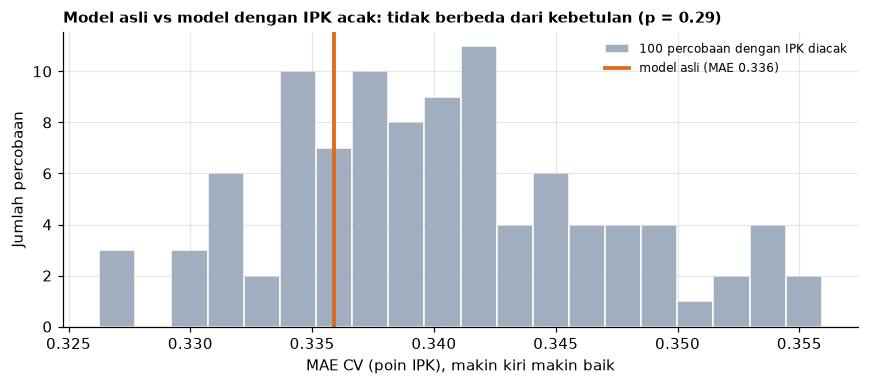

Disimpan: figures_and_outputs\B5_4_uji_permutasi.png


In [29]:
rf_uji = clone(grid_rf.best_estimator_).set_params(model__n_estimators=200)
skor_asli, skor_acak, p_perm = permutation_test_score(
    rf_uji, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error",
    n_permutations=100, random_state=SEED)
print(f"MAE CV model asli          : {-skor_asli:.3f}")
print(f"MAE CV dengan IPK diacak   : rata-rata {-skor_acak.mean():.3f} (rentang {-skor_acak.max():.3f} - {-skor_acak.min():.3f})")
print(f"p-value uji permutasi      : {p_perm:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(-skor_acak, bins=20, color=ABU, edgecolor="white", label="100 percobaan dengan IPK diacak")
ax.axvline(-skor_asli, color=ORANYE, lw=2.5, label=f"model asli (MAE {-skor_asli:.3f})")
ax.set_xlabel("MAE CV (poin IPK), makin kiri makin baik")
ax.set_ylabel("Jumlah percobaan")
kesimpulan = "ada sinyal" if p_perm < 0.05 else "tidak berbeda dari kebetulan"
ax.set_title(f"Model asli vs model dengan IPK acak: {kesimpulan} (p = {p_perm:.2f})", loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
simpan_fig(fig, "B5_4_uji_permutasi")

**Interpretasi B5.4**
- MAE CV model asli **0,336**, sedangkan 100 model yang dilatih dengan IPK acak rata-rata **0,340** (rentang 0,326–0,356). Garis oranye (model asli) berada **di tengah-tengah** sebaran abu-abu.
- p-value **0,29**: 29% percobaan dengan IPK acak sama baik atau lebih baik daripada model asli. Jauh di atas 0,05.
- **Artinya:** keunggulan model asli atas model "asal tebak" **tidak bisa dibedakan dari kebetulan**. Ini bukti tambahan, dengan cara yang berbeda dari B3.4, bahwa jawaban VARK di data ini hampir tidak membawa informasi tentang IPK.

## B5.5 Perbandingan semua model (cross-validation di data train)

,MAE CV,MAE CV (SD),RMSE CV,R2 CV,R2 CV (SD),MAE train,R2 train
Baseline (rata-rata),0.336,0.053,0.446,-0.081,0.062,0.328,0.000
Linear Regression,0.507,0.061,0.666,-1.460,0.411,0.194,0.702
Random Forest (default),0.354,0.037,0.456,-0.153,0.170,0.125,0.862
Random Forest (tuning),0.336,0.043,0.444,-0.073,0.070,0.221,0.526
Ridge (opsional),0.336,0.052,0.446,-0.079,0.062,0.321,0.040


Disimpan: figures_and_outputs\B5_5_perbandingan_cv.csv


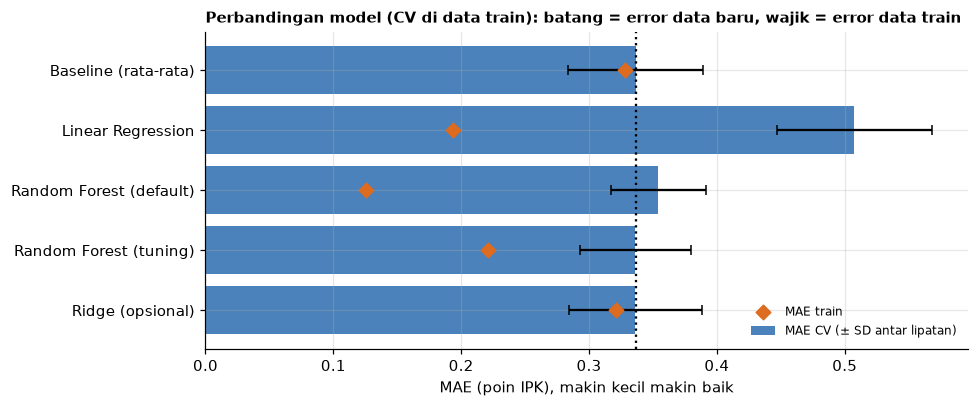

Disimpan: figures_and_outputs\B5_5_perbandingan_model_cv.png


In [30]:
urutan = ["Baseline (rata-rata)", "Linear Regression", "Random Forest (default)", "Random Forest (tuning)", "Ridge (opsional)"]
hasil_cv = hasil_cv.loc[urutan].astype(float)
display(hasil_cv.round(3))
simpan_tabel(hasil_cv.round(4), "B5_5_perbandingan_cv")

fig, ax = plt.subplots(figsize=(9, 3.8))
posisi = np.arange(len(urutan))
ax.barh(posisi, hasil_cv["MAE CV"], xerr=hasil_cv["MAE CV (SD)"], color=BIRU, alpha=0.85,
        error_kw=dict(ecolor="black", capsize=3), label="MAE CV (± SD antar lipatan)")
ax.scatter(hasil_cv["MAE train"], posisi, color=ORANYE, zorder=3, s=45, marker="D", label="MAE train")
ax.axvline(hasil_cv.loc["Baseline (rata-rata)", "MAE CV"], color="black", ls=":", lw=1.5)
ax.set_yticks(posisi, urutan)
ax.invert_yaxis()
ax.set_xlabel("MAE (poin IPK), makin kecil makin baik")
ax.set_title("Perbandingan model (CV di data train): batang = error data baru, wajik = error data train",
             loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
simpan_fig(fig, "B5_5_perbandingan_model_cv")

**Interpretasi B5.5**
- **Tidak ada model yang jelas lebih baik dari baseline.** MAE CV terbaik (RF tuning, Ridge, dan baseline) sama-sama **0,336**, dan perbedaannya jauh lebih kecil dari SD antar lipatan (±0,04–0,05). Semua R² CV bernilai negatif.
- **Linear Regression paling buruk** (MAE CV 0,507), dan **RF default** juga lebih buruk dari baseline (0,354).
- **Jarak antara wajik oranye (error train) dan ujung batang biru (error CV)** menunjukkan seberapa besar model menghafal: paling jauh pada RF default dan LR, makin dekat pada RF tuning, dan hampir berimpit pada Ridge dan baseline.
- **Artinya:** dengan 64 fitur VARK, model terbaik pun hanya setara dengan menebak rata-rata IPK. Ini bukan kesalahan proses; ini temuan bahwa preferensi VARK (pada data ini) tidak membantu memperkirakan IPK, sesuai EDA di B3.4.

## B5.6 Model yang dipilih untuk evaluasi test
Sesuai aturan di awal B5: dari dua model wajib, dipilih yang MAE CV-nya paling kecil.

In [31]:
kandidat = hasil_cv.loc[["Linear Regression", "Random Forest (tuning)"], "MAE CV"]
NAMA_TERPILIH = kandidat.idxmin()
# Latih ulang kandidat di seluruh 138 baris train (RF sudah otomatis di-refit oleh GridSearch)
MODEL_FINAL = {"Linear Regression": clone(PIPELINES["Linear Regression"]).fit(X_train, y_train),
               "Random Forest (tuning)": grid_rf.best_estimator_}

print("MAE CV kandidat:", kandidat.round(3).to_dict())
print("Model terpilih :", NAMA_TERPILIH)
print("Parameter      :", {k.replace("model__", ""): v for k, v in grid_rf.best_params_.items()}
      if "Forest" in NAMA_TERPILIH else "tanpa hyperparameter")

MAE CV kandidat: {'Linear Regression': 0.507, 'Random Forest (tuning)': 0.336}
Model terpilih : Random Forest (tuning)
Parameter      : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 3}


**Keputusan B5.6**
- **Random Forest (tuning)** dipilih karena MAE CV-nya (0,336) jauh lebih kecil daripada Linear Regression (0,507).
- Perlu dicatat dengan jujur: RF dipilih karena **lebih baik dari LR**, bukan karena lebih baik dari baseline. Keduanya setara.
- Parameter: `n_estimators = 500`, `min_samples_leaf = 3`, `max_features = "sqrt"`, `max_depth = 5`, `random_state = 42`. Model ini sudah dilatih ulang di seluruh 138 baris train (`refit`) dan inilah yang akan disimpan di B7.
- **Langkah berikutnya (B6):** Baseline, Linear Regression, dan Random Forest (+ Ridge sebagai pembanding) dievaluasi **satu kali** pada 35 baris test yang belum pernah disentuh.

---
# B6 – Evaluasi pada data test

Di bagian ini data test (35 baris) dipakai **untuk pertama dan satu-satunya kali**. Semua model dan parameternya sudah dikunci di B5, jadi tidak ada yang diubah setelah melihat hasil di sini.

**Model yang dievaluasi:**
- **Baseline (rata-rata):** patokan minimum.
- **Linear Regression** dan **Random Forest (tuning)**: dua model wajib. RF adalah model terpilih (B5.6).
- **Ridge (opsional):** hanya pembanding.

**Metrik (Panduan Regresi bagian 5):**

| Metrik | Arti | Cara membaca |
|---|---|---|
| **MAE** | Rata-rata selisih absolut IPK asli dan tebakan | Satuannya poin IPK. Makin kecil makin baik |
| **RMSE** | Mirip MAE, tetapi tebakan yang meleset jauh dihukum lebih berat | Makin kecil makin baik. Kalau jauh lebih besar dari MAE, ada beberapa tebakan yang meleset jauh |
| **R²** | Seberapa jauh lebih baik dari menebak rata-rata | 1 = sempurna, 0 = sama dengan menebak rata-rata, negatif = lebih buruk dari menebak rata-rata |

## B6.1 Tabel metrik: train, cross-validation, dan test
Format tabel mengikuti ringkasan di praktikum Modul 5 (R² train vs R² test, MAE test), ditambah MAE CV dari B5 supaya terlihat apakah hasil test konsisten dengan hasil cross-validation.

Karena test hanya 35 baris, selisih kecil antar model bisa muncul karena kebetulan. Untuk itu dihitung juga **interval kepercayaan bootstrap 95%** untuk selisih MAE RF dan baseline: 35 baris test diambil ulang secara acak (boleh berulang) sebanyak 5.000 kali, dan selisih MAE dihitung setiap kali. Kalau intervalnya **mencakup 0**, RF belum terbukti lebih baik dari baseline.

In [ ]:
MODEL_UJI = {
    "Baseline (rata-rata)":   clone(PIPELINES["Baseline (rata-rata)"]).fit(X_train, y_train),
    "Linear Regression":      MODEL_FINAL["Linear Regression"],
    "Random Forest (tuning)": MODEL_FINAL["Random Forest (tuning)"],
    "Ridge (opsional)":       grid_ridge.best_estimator_,
}

pred_test = pd.DataFrame({nama: m.predict(X_test) for nama, m in MODEL_UJI.items()}, index=X_test.index)
pred_train = pd.DataFrame({nama: m.predict(X_train) for nama, m in MODEL_UJI.items()}, index=X_train.index)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

hasil_test = pd.DataFrame({
    nama: {
        "R2 train": r2_score(y_train, pred_train[nama]),
        "R2 test": r2_score(y_test, pred_test[nama]),
        "MAE train": mean_absolute_error(y_train, pred_train[nama]),
        "MAE CV (B5)": hasil_cv.loc[nama, "MAE CV"] if nama in hasil_cv.index else np.nan,
        "MAE test": mean_absolute_error(y_test, pred_test[nama]),
        "RMSE test": rmse(y_test, pred_test[nama]),
        "tebakan di luar 0-4": int(((pred_test[nama] < 0) | (pred_test[nama] > 4)).sum()),
    } for nama in MODEL_UJI
}).T
hasil_test["MAE test - baseline"] = hasil_test["MAE test"] - hasil_test.loc["Baseline (rata-rata)", "MAE test"]
display(hasil_test.round(3))
simpan_tabel(hasil_test.round(4), "B6_1_metrik_test")

print(f"Sebagai skala: simpangan baku IPK test = {y_test.std():.2f}, rentang IPK test = {y_test.min():.2f}-{y_test.max():.2f}")

# Apakah keunggulan RF atas baseline di test nyata atau kebetulan? Bootstrap selisih MAE (5.000 kali)
err_rf = (y_test - pred_test["Random Forest (tuning)"]).abs().to_numpy()
err_baseline = (y_test - pred_test["Baseline (rata-rata)"]).abs().to_numpy()
selisih = err_rf - err_baseline
rng = np.random.default_rng(SEED)
boot = np.array([selisih[rng.integers(0, len(selisih), len(selisih))].mean() for _ in range(5000)])
ci_bawah, ci_atas = np.percentile(boot, [2.5, 97.5])
print(f"Selisih MAE test RF - baseline: {selisih.mean():+.3f} poin IPK "
      f"(95% CI bootstrap {ci_bawah:+.3f} s.d. {ci_atas:+.3f}; mencakup 0: {ci_bawah < 0 < ci_atas})")

**Interpretasi B6.1**
- **Random Forest (model terpilih)** rata-rata meleset **0,345 poin IPK** di test (R² 0,07). Baseline meleset 0,356 (R² ≈ 0). Jadi RF hanya lebih baik **0,011 poin IPK** (sekitar 3%). Ridge berada di antaranya (MAE 0,350, R² 0,03).
- **Linear Regression paling buruk:** MAE 0,402, R² **−0,34** (lebih buruk dari menebak rata-rata), dan 3 dari 35 tebakannya di atas 4,00.
- **Apakah RF benar-benar lebih baik dari baseline?** Interval bootstrap selisih MAE adalah **−0,029 s.d. +0,007**, yang **mencakup 0**. Artinya keunggulan 0,011 poin itu masih bisa terjadi karena kebetulan. Ini konsisten dengan B5: di CV keduanya sama-sama 0,336, dan uji permutasi p = 0,29.
- **Train vs test:** R² train RF 0,51 tetapi R² test hanya 0,07. Walaupun sudah direm, RF masih sedikit "menghafal" data train. LR lebih parah (0,59 vs −0,34).
- **Dalam skala IPK:** meleset rata-rata 0,35 poin itu besar. Simpangan baku IPK test sendiri hanya 0,45, jadi error model hampir sebesar variasi alami IPK. Contohnya, mahasiswa ber-IPK 3,00 bisa ditebak 3,35.
- **Catatan B4.2:** MAE test LR (0,402) lebih kecil dari MAE CV-nya (0,507), sebagian karena 3 IPK terendah tidak ada di test dan test hanya 35 baris. Urutan model tetap sama dengan di CV.

## B6.2 Grafik IPK aktual vs prediksi
Setiap titik adalah satu mahasiswa di data test. **Garis diagonal** = tebakan sempurna (prediksi = aktual). **Garis titik-titik** = tebakan baseline (rata-rata IPK train). Model yang bagus membuat titik-titik mengikuti garis diagonal.

In [ ]:
batas = (min(y_test.min(), pred_test.min().min()) - 0.1, max(4.0, pred_test.max().max()) + 0.1)
rata_train = y_train.mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, nama, warna in zip(axes, ["Linear Regression", "Random Forest (tuning)", "Ridge (opsional)"], [ORANYE, BIRU, "#38a169"]):
    ax.scatter(y_test, pred_test[nama], color=warna, alpha=0.75, s=30, edgecolor="white")
    ax.plot(batas, batas, color="black", lw=1, label="prediksi = aktual")
    ax.axhline(rata_train, color=ABU, ls=":", lw=2, label=f"baseline ({rata_train:.2f})")
    ax.axhspan(4.0, batas[1], color="#fed7d7", alpha=0.5, label="IPK > 4 (mustahil)")
    ax.set_xlim(batas); ax.set_ylim(batas)
    ax.set_title(f"{nama}\nMAE {hasil_test.loc[nama, 'MAE test']:.3f} | R² {hasil_test.loc[nama, 'R2 test']:.2f}",
                 fontsize=9, fontweight="bold")
    ax.set_xlabel("IPK aktual")
axes[0].set_ylabel("IPK prediksi")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.suptitle(f"IPK aktual vs prediksi pada data test (n = {len(y_test)})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B6_2_aktual_vs_prediksi")

**Interpretasi B6.2**
- **Linear Regression (kiri):** titik-titik menyebar ke mana-mana dan tidak mengikuti garis diagonal. Ada tebakan yang masuk zona merah (> 4,00, mustahil) dan ada mahasiswa ber-IPK 3,05 yang ditebak 2,55. Tebakannya "berani" tetapi tidak tepat.
- **Random Forest (tengah) dan Ridge (kanan):** semua titik membentuk garis **hampir datar** di sekitar 3,36 (RF: 3,22–3,48), apa pun IPK aslinya. Model "bermain aman" dengan menebak dekat rata-rata untuk semua orang, sehingga tidak bisa membedakan mahasiswa ber-IPK tinggi dan rendah.
- **Artinya:** tidak ada model yang titiknya mengikuti garis diagonal. Pola "tebakan menumpuk di rata-rata" ini disebut *regression to the mean*, dan terjadi karena fitur VARK tidak membawa informasi yang cukup tentang IPK (B3.4, B5.4).

## B6.3 Grafik residual
**Residual = IPK aktual − IPK prediksi.** Residual positif berarti tebakan terlalu rendah, residual negatif berarti tebakan terlalu tinggi. Kalau model baik, residual tersebar acak di sekitar 0 tanpa pola.

In [ ]:
residual = pd.DataFrame({nama: y_test - pred_test[nama] for nama in MODEL_UJI}, index=X_test.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, nama, warna in zip(axes, ["Linear Regression", "Random Forest (tuning)"], [ORANYE, BIRU]):
    ax.scatter(y_test, residual[nama], color=warna, alpha=0.75, s=30, edgecolor="white")
    ax.axhline(0, color="black", lw=1)
    kemiringan, potong = np.polyfit(y_test, residual[nama], 1)
    xs = np.linspace(y_test.min(), y_test.max(), 50)
    ax.plot(xs, kemiringan * xs + potong, color=warna, ls="--", lw=1.5, label=f"tren residual (kemiringan {kemiringan:.2f})")
    ax.set_title(nama, fontsize=10, fontweight="bold")
    ax.set_xlabel("IPK aktual")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("Residual (aktual - prediksi)")
fig.suptitle("Residual di data test: di atas 0 = tebakan terlalu rendah, di bawah 0 = terlalu tinggi",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
simpan_fig(fig, "B6_3_residual")

**Interpretasi B6.3**
- **Random Forest (kanan):** residual membentuk **garis lurus yang naik** dengan kemiringan hampir 1 (0,96). Artinya tebakan RF hampir konstan, sehingga residual hampir sama dengan "IPK aktual dikurangi rata-rata". Mahasiswa ber-IPK rendah selalu ditebak terlalu tinggi (residual sampai −1,12), dan yang ber-IPK tinggi ditebak terlalu rendah (sampai +0,64).
- **Linear Regression (kiri):** polanya serupa (kemiringan 0,70), tetapi lebih acak-acakan karena tebakannya ikut berubah-ubah mengikuti noise.
- **Artinya:** residual yang baik seharusnya tersebar acak di sekitar 0 tanpa pola. Pola miring yang jelas ini menunjukkan model **tidak menangkap apa yang membuat IPK seseorang tinggi atau rendah**.

## B6.4 Error per kelompok IPK
Di B3.2 diperkirakan error terbesar akan ada pada IPK rendah, karena IPK rendah jarang di data. Dugaan itu dicek di sini dengan MAE per kelompok IPK.

In [ ]:
kelompok = pd.cut(y_test, bins=[0, 3.0, 3.5, 4.01], right=False, labels=["< 3,00", "3,00 - 3,49", ">= 3,50"])
error_kelompok = (residual.abs().assign(kelompok=kelompok)
                  .groupby("kelompok", observed=True)
                  .agg(**{"n": ("Baseline (rata-rata)", "size")},
                       **{f"MAE {n}": (n, "mean") for n in ["Baseline (rata-rata)", "Linear Regression", "Random Forest (tuning)"]}))
display(error_kelompok.round(3))
simpan_tabel(error_kelompok.round(4), "B6_4_error_per_kelompok_ipk")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
lebar = 0.27
for k, (nama, warna) in enumerate(zip(["Baseline (rata-rata)", "Linear Regression", "Random Forest (tuning)"], [ABU, ORANYE, BIRU])):
    ax.bar(np.arange(len(error_kelompok)) + (k - 1) * lebar, error_kelompok[f"MAE {nama}"], lebar, color=warna, label=nama)
ax.set_xticks(range(len(error_kelompok)),
              [f"IPK {i}\n(n = {n})" for i, n in zip(error_kelompok.index, error_kelompok["n"])])
ax.set_ylabel("MAE (poin IPK)")
ax.set_title(f"MAE per kelompok IPK: error terbesar pada kelompok IPK {error_kelompok['MAE Random Forest (tuning)'].idxmax()}",
             loc="left", fontsize=10, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
simpan_fig(fig, "B6_4_error_per_kelompok_ipk")

**Interpretasi B6.4**
- **IPK < 3,00 (7 orang):** error semua model paling besar (MAE 0,61–0,67), sekitar **dua kali lipat** kelompok lain. Dugaan di B3.2 terbukti: IPK rendah jarang di data, jadi model selalu menebaknya terlalu tinggi.
- **IPK 3,00–3,49 (12 orang):** error baseline dan RF kecil (0,13–0,14), karena IPK mereka memang dekat rata-rata sehingga tebakan "rata-rata" kebetulan pas. LR justru meleset dua kali lebih jauh (0,26) karena tebakannya liar.
- **IPK ≥ 3,50 (16 orang):** error sedang (0,37–0,42); tebakan terlalu rendah.
- LR sedikit lebih baik di IPK < 3,00 (0,61) karena tebakannya lebih menyebar, tetapi itu dibayar dengan error dua kali lipat di kelompok tengah.
- **Artinya:** model hanya "tepat" untuk mahasiswa yang IPK-nya memang dekat rata-rata. Untuk mahasiswa yang IPK-nya jauh dari rata-rata (justru yang paling penting dikenali), model tidak membantu.

## B6.5 Lima kesalahan terbesar model terpilih
Contoh kesalahan ditelusuri ke ID responden (ID hanya untuk analisis, bukan fitur). Kolom "jumlah opsi dipilih" ditampilkan sebagai konteks pola jawaban (B3.3), tidak dipakai model.

In [ ]:
terbesar = (pd.DataFrame({
    "ID": id_test,
    "IPK aktual": y_test,
    "prediksi RF": pred_test["Random Forest (tuning)"],
    "error RF (aktual - prediksi)": residual["Random Forest (tuning)"],
    "prediksi LR": pred_test["Linear Regression"],
    "jumlah opsi dipilih": X_test.sum(axis=1),
}).assign(abs_error=lambda d: d["error RF (aktual - prediksi)"].abs())
  .sort_values("abs_error", ascending=False).drop(columns="abs_error").head(5).set_index("ID"))
display(terbesar.round(2))
simpan_tabel(terbesar.round(3), "B6_5_lima_error_terbesar")
print(f"Rentang prediksi RF di test: {pred_test['Random Forest (tuning)'].min():.2f} - {pred_test['Random Forest (tuning)'].max():.2f} "
      f"(IPK aktual: {y_test.min():.2f} - {y_test.max():.2f})")

**Interpretasi B6.5**
- **4 dari 5 kesalahan terbesar adalah mahasiswa ber-IPK rendah** (2,24–2,72) yang ditebak 3,22–3,36. Satu lagi mahasiswa ber-IPK tinggi (3,89) yang ditebak 3,25.
- Kesalahan terbesar: **ID 134** (IPK 2,24, ditebak 3,36, meleset 1,12 poin). Di kasus ini LR kebetulan lebih dekat (2,75), tetapi secara keseluruhan LR tetap lebih buruk (B6.1).
- Tebakan RF di seluruh test hanya berkisar **3,22–3,48**, padahal IPK aslinya 2,24–3,99. Model tidak pernah berani menebak IPK rendah atau tinggi.
- Tiga dari lima mahasiswa ini memilih tepat 16 opsi ("pemilih tegas", B3.3). Dengan hanya 5 orang, ini sekadar pengamatan, bukan pola yang bisa disimpulkan.
- **Penyebab:** jawaban VARK mahasiswa ber-IPK rendah tidak berbeda jelas dari mahasiswa ber-IPK rata-rata, sehingga model tidak punya petunjuk untuk menebak lebih rendah.

## B6.6 *(Opsional)* Fitur mana yang paling dipakai Random Forest?
**Permutation importance** mengukur seberapa besar error test naik kalau satu fitur diacak. Kalau mengacak suatu fitur membuat error naik jelas, berarti model bergantung pada fitur itu. Diulang 30 kali per fitur supaya terlihat seberapa stabil hasilnya.

**Catatan:** importance hanya menunjukkan fitur yang **dipakai model**, bukan penyebab IPK.

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(MODEL_FINAL["Random Forest (tuning)"], X_test, y_test,
                             scoring="neg_mean_absolute_error", n_repeats=30, random_state=SEED)
tabel_imp = (pd.DataFrame({"kenaikan MAE (rata-rata)": imp.importances_mean, "SD": imp.importances_std}, index=FEATURE_COLS)
             .sort_values("kenaikan MAE (rata-rata)", ascending=False))
tabel_imp["jelas > 0 (rata-rata > 2 SD)"] = tabel_imp["kenaikan MAE (rata-rata)"] > 2 * tabel_imp["SD"]
display(tabel_imp.head(10).round(4))
print(f"Fitur yang kenaikan MAE-nya jelas di atas 0: {int(tabel_imp['jelas > 0 (rata-rata > 2 SD)'].sum())} dari 64")
simpan_tabel(tabel_imp.round(5), "B6_6_permutation_importance")

top = tabel_imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top["kenaikan MAE (rata-rata)"], xerr=top["SD"], color=BIRU, alpha=0.85, error_kw=dict(capsize=3))
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Kenaikan MAE test jika fitur diacak (poin IPK)")
ax.set_title("10 fitur dengan importance tertinggi (Random Forest, data test)", loc="left", fontsize=10, fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B6_6_permutation_importance")

**Interpretasi B6.6**
- Tiga fitur teratas semuanya opsi **Aural** (`VARK_Q01_A`, `VARK_Q16_A`, `VARK_Q04_A`). Ini sejalan dengan B3.4, di mana korelasi tertinggi dengan IPK juga dari opsi Aural.
- Namun pengaruhnya **sangat kecil**: mengacak fitur terpenting hanya menaikkan MAE **0,0045 poin IPK**, dan hanya 3 dari 64 fitur yang kenaikannya jelas di atas 0.
- **Artinya:** RF memang sedikit memakai pola "memilih opsi mendengar/berdiskusi → IPK sedikit lebih tinggi", tetapi pola itu terlalu lemah untuk membuat tebakan yang berguna. Ini juga **bukan sebab-akibat**: memilih opsi Aural tidak membuat IPK naik.

## B6.7 Kesimpulan evaluasi & keterbatasan

| Pertanyaan | Jawaban |
|---|---|
| Model mana yang terbaik di test? | **Random Forest (tuning):** MAE 0,345, RMSE 0,427, R² 0,07. Linear Regression paling buruk (MAE 0,402, R² −0,34) |
| Apakah lebih baik dari menebak rata-rata? | Hanya 0,011 poin IPK, dan interval bootstrap-nya mencakup 0, jadi **secara praktis setara dengan baseline** |
| Apakah hasil test konsisten dengan CV? | Ya. Di CV, RF = baseline = 0,336; di test RF sedikit lebih baik, masih dalam batas kebetulan. Urutan model sama |
| Bagaimana pola kesalahannya? | Tebakan menumpuk di 3,2–3,5. IPK rendah selalu ditebak terlalu tinggi, IPK tinggi terlalu rendah |
| Siapa yang paling sulit ditebak? | Mahasiswa dengan IPK < 3,00 (MAE ±0,65) |

**Keterbatasan yang perlu diingat:**
- **Data test kecil (35 baris).** Satu mahasiswa ≈ 3% data test, jadi angka metrik bisa berubah cukup besar dengan pembagian data yang berbeda.
- **Test tidak memuat 3 IPK terendah** (semuanya di train, B4.2), sehingga kasus tersulit tidak ikut diuji.
- **Korelasional, bukan sebab-akibat.** Urutan waktu pengisian survei dan IPK tidak diketahui, jadi model ini juga **bukan prediksi dini**.
- **Sampel tidak acak dan terbatas:** responden dari jaringan kelompok, didominasi angkatan 2024, dan IPK dipengaruhi banyak hal lain yang tidak ada di survei (program studi, beban SKS, motivasi, dan lain-lain).
- **Model tidak layak dipakai untuk menilai atau meramal IPK mahasiswa.** Di aplikasi Streamlit, model ini hanya demonstrasi alur machine learning, dengan peringatan yang jelas.

**Model yang disimpan di B7:** Random Forest (tuning), sesuai aturan di B5.6. Pilihan ini **tidak diubah** setelah melihat hasil test.